# 03 · Arquitecturas eficientes y entrenamiento a gran escala

Este es un módulo de Neural Networks 1002. Supone conocidos el [módulo 09 de Neural Networks 1001](https://neural-networks.academy.forwardforecasting.eu/es/09-transformer/) (el transformer: atención, atención multicabeza, el bloque decodificador), el [módulo 10](https://neural-networks.academy.forwardforecasting.eu/es/10-gpt-desde-cero/) (modelos de lenguaje grandes, un GPT entrenado desde cero, la caché de claves y valores) y el [módulo 02 de Neural Networks 1002](https://neural-networks-1002.academy.forwardforecasting.eu/es/02-modelos-abiertos-y-ajuste-fino/) (modelos abiertos, ajuste fino y cuantización).

Los modelos modernos están limitados menos por las ideas que por la aritmética y la memoria. Un modelo de 70 000 millones de parámetros no cabe en un solo acelerador, un texto largo vuelve la atención cuadráticamente cara, y entrenar un modelo puede consumir tanta electricidad como cientos de hogares en un año. Este módulo abre la caja negra del **coste**: de dónde viene, qué trucos de arquitectura lo reducen y cómo se reparte el entrenamiento entre muchas máquinas. Todo se mide en la CPU de un portátil con semillas fijas, y tres modelos reales preentrenados (un pequeño modelo de mezcla de expertos, un pequeño modelo de espacio de estados y un transformer comparable) muestran los mismos efectos en un diseño realista.

En este cuaderno:

1. construirás una **calculadora de costes** (la regla práctica 6ND para las operaciones de coma flotante del entrenamiento, y la memoria de parámetros, gradientes, estado del optimizador, activaciones y caché de claves y valores) y la aplicarás a tamaños de modelos publicados, y después comprobarás la regla contando en una red pequeña;
2. implementarás la **atención por bloques al estilo FlashAttention** con el softmax en línea, comprobarás que da la misma salida que la atención normal y medirás su memoria y su tiempo;
3. medirás cómo la **atención multi-consulta y la atención de consultas agrupadas** reducen la caché de claves y valores (KV, key-value), en bytes, en tiempo de decodificación y en calidad del modelo;
4. verás el **contexto largo**: los embeddings de posición rotatorios (RoPE, rotary position embeddings) y la atención de ventana deslizante;
5. implementarás una pequeña **mezcla de expertos** (MoE, mixture of experts) con un enrutador top-k y una pérdida de balance de carga, medirás la calidad frente a los parámetros activos, observarás el **colapso de expertos** e inspeccionarás el enrutamiento de un MoE real pequeño;
6. derivarás los **modelos de espacio de estados** (S4 y Mamba) a partir de una recurrencia lineal y su escaneo paralelo, los compararás con la atención en una tarea de largo alcance y ejecutarás un Mamba real pequeño junto a un transformer entrenado con los mismos datos;
7. entrenarás a gran escala: **precisión mixta** (bfloat16 en CPU y la numérica de fp16), **acumulación de gradientes**, **checkpointing de gradientes** (recomputación de activaciones) y **paralelismo de datos ejecutado de verdad** en varios procesos de CPU con `torch.distributed`, además del reparto en paralelismo de tensores, de tubería y ZeRO/FSDP explicado y calculado;
8. abaratarás la inferencia: **cuantización**, **decodificación especulativa** (con una simulación medida) y **destilación**;
9. pondrás cifras honestas a la **energía y el coste** del entrenamiento y la inferencia.

**Contenido**

1. Dónde está el coste de un transformer
2. El coste de la atención y FlashAttention
3. Atención multi-consulta y de consultas agrupadas
4. Contexto largo: RoPE y ventanas deslizantes
5. Mezcla de expertos
6. Modelos de espacio de estados: S4 y Mamba
7. Entrenar a gran escala
8. Eficiencia en la inferencia
9. Energía y coste
10. Ideas clave, ejercicios, referencias

| Se apoya en | Qué reutilizamos |
|---|---|
| [09 Transformer (1001)](https://neural-networks.academy.forwardforecasting.eu/es/09-transformer/) | consultas, claves, valores, la matriz de atención, el bloque decodificador |
| [10 LLM (1001)](https://neural-networks.academy.forwardforecasting.eu/es/10-gpt-desde-cero/) | entrenamiento por siguiente token, la caché KV, por qué la generación es secuencial |
| [03 Entrenar redes profundas (1001)](https://neural-networks.academy.forwardforecasting.eu/es/03-entrenar-bien-redes-profundas/) | Adam, minilotes, leer curvas de pérdida |
| [02 Modelos abiertos, aprendizaje por transferencia y ajuste fino (1002)](https://neural-networks-1002.academy.forwardforecasting.eu/es/02-modelos-abiertos-y-ajuste-fino/) | cuantización, ajuste fino eficiente en parámetros, el código de carga de Hugging Face |

¿Nuevo en PyTorch? El [curso Python 1001, sección de frameworks de IA](https://python.academy.forwardforecasting.eu/es/11-frameworks-de-ia/) lo introduce.

**Datos, modelos y en qué se diferencian los juguetes de los sistemas reales.** Los experimentos de juguete usan datos generados en el cuaderno, más el código fuente de la biblioteca estándar de Python como un texto real pequeño (un modelo de lenguaje a nivel de carácter). Modelos reales, descargados una vez del Hugging Face Hub y guardados en caché en el primer uso: `ibm-granite/granite-3.0-1b-a400m-base` (un MoE de 1300 millones de parámetros, licencia Apache 2.0, [ficha del modelo](https://huggingface.co/ibm-granite/granite-3.0-1b-a400m-base)), `state-spaces/mamba-130m-hf` ([ficha del modelo](https://huggingface.co/state-spaces/mamba-130m-hf); la ficha no indica licencia, el repositorio de código de los autores es Apache 2.0, consulta los términos antes de cualquier uso comercial) y `EleutherAI/pythia-160m` (Apache 2.0, [ficha del modelo](https://huggingface.co/EleutherAI/pythia-160m)); unos 6 GB en total (el checkpoint de Granite está guardado en 32 bits). Los juguetes usan redes de unos cientos de miles de parámetros y secuencias de como máximo unos pocos miles de tokens; los sistemas reales son de 10 000 a 1 000 000 de veces mayores, corren en miles de aceleradores con núcleos fusionados de GPU (graphics processing unit, unidad de procesamiento gráfico) y están limitados por el ancho de banda de memoria y la velocidad de red de maneras que una CPU solo imita. Los métodos y la aritmética se trasladan, los tiempos exactos no.

**Tiempo y hardware.** El cuaderno no necesita GPU ni paquetes adicionales (usa `torch`, `transformers`, `numpy`, `scipy` y `matplotlib`, todos preinstalados en Google Colab). En un entorno limpio de 2 CPU tardó unos 8 minutos (la primera vez se suman unos 6 GB de descargas de modelos) y el pico de memoria fue de unos 9 GB, así que en un entorno gratuito de Colab (unos 12 GB) conviene cerrar otras sesiones antes. El experimento multiproceso de la sección 7.3 usa como máximo `os.cpu_count()` trabajadores, así que en Colab muestra 1 y 2 trabajadores, no 4; los números citados en las lecturas vienen de una máquina de 32 vCPU con 4 trabajadores, y todos los tiempos (pero no los recuentos de memoria ni las comprobaciones exactas) cambian con el hardware.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/fborbon/academy/blob/main/neural-networks-1002/es/03_arquitecturas_eficientes_y_escala.ipynb)

**¿Lo ejecutas en Google Colab?** Elige *Entorno de ejecución > Ejecutar todo*. La primera celda de código instala solo lo que falta (no hace falta reiniciar la sesión). **Tiempo medido** en un entorno limpio de 2 CPU como el de Colab: unos 8 minutos, con un pico de memoria de unos 8,9 GB (las descargas de modelos y datos se hicieron con una conexión rápida). Una CPU gratuita de Colab suele ser más lenta que la máquina usada para medir, así que cuenta con más tiempo; los tiempos impresos en las salidas guardadas vienen de una máquina con varios núcleos.

In [ ]:
# Preparación: funciona en local y en Google Colab. Instala solo los paquetes que faltan.
import importlib.util, os, subprocess, sys

IN_COLAB = 'google.colab' in sys.modules
_NEEDED = {
    'matplotlib': 'matplotlib',
    'numpy': 'numpy',
    'sklearn': 'scikit-learn',
    'torch': 'torch',
    'transformers': 'transformers',
}  # import name -> pip requirement
_missing = [req for mod, req in _NEEDED.items() if importlib.util.find_spec(mod) is None]
if _missing:
    print('Instalando:', ', '.join(_missing))
    _r = subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *_missing], capture_output=True, text=True)
    if _r.returncode:
        print('ADVERTENCIA: la instalación con pip falló; se continúa. Detalle:\n' + _r.stderr[-400:])
print(f"Entorno: Python {sys.version.split()[0]} | {'Google Colab' if IN_COLAB else 'local'} | CPUs: {os.cpu_count()}")

In [1]:
import warnings
warnings.filterwarnings("ignore")
import os, sys, time, math, json, subprocess, tempfile, statistics, glob, sysconfig
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

NT = int(os.environ.get("OMP_NUM_THREADS", "2"))      # hilos que usa este cuaderno
torch.set_num_threads(NT)
torch.manual_seed(0); np.random.seed(0)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
T_START = time.time()
WORK = tempfile.mkdtemp(prefix="nn03_")                # carpeta temporal para módulos auxiliares y scripts de subprocesos
sys.path.insert(0, WORK)

TINYLM_SRC = '''
import math, torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.checkpoint import checkpoint

class Block(nn.Module):
    # bloque decodificador pre-norm con H cabezas de consulta y Hkv cabezas de clave/valor (Hkv = H es atención multicabeza normal)
    def __init__(self, d, H, Hkv):
        super().__init__()
        self.H, self.Hkv, self.dh = H, Hkv, d // H
        self.n1, self.n2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.wq = nn.Linear(d, d, bias=False)
        self.wk = nn.Linear(d, Hkv * self.dh, bias=False)
        self.wv = nn.Linear(d, Hkv * self.dh, bias=False)
        self.wo = nn.Linear(d, d, bias=False)
        self.up, self.down = nn.Linear(d, 4 * d, bias=False), nn.Linear(4 * d, d, bias=False)

    def forward(self, x):
        B, n, d = x.shape
        h = self.n1(x)
        q = self.wq(h).view(B, n, self.H, self.dh).transpose(1, 2)
        k = self.wk(h).view(B, n, self.Hkv, self.dh).transpose(1, 2)
        v = self.wv(h).view(B, n, self.Hkv, self.dh).transpose(1, 2)
        g = self.H // self.Hkv
        k, v = k.repeat_interleave(g, 1), v.repeat_interleave(g, 1)       # cada cabeza de clave/valor atiende a g cabezas de consulta
        s = (q @ k.transpose(-1, -2)) / math.sqrt(self.dh)
        s = s.masked_fill(torch.triu(torch.ones(n, n, dtype=torch.bool), 1), float("-inf"))
        a = (s.softmax(-1) @ v).transpose(1, 2).reshape(B, n, d)
        x = x + self.wo(a)
        return x + self.down(F.gelu(self.up(self.n2(x))))

class TinyLM(nn.Module):
    def __init__(self, V=256, d=128, L=3, H=8, Hkv=None, n_max=512, ckpt=False):
        super().__init__()
        self.ckpt = ckpt
        self.emb, self.pos = nn.Embedding(V, d), nn.Embedding(n_max, d)
        self.blocks = nn.ModuleList([Block(d, H, Hkv or H) for _ in range(L)])
        self.nf, self.head = nn.LayerNorm(d), nn.Linear(d, V, bias=False)

    def forward(self, idx):
        x = self.emb(idx) + self.pos(torch.arange(idx.shape[1]))
        for b in self.blocks:
            x = checkpoint(b, x, use_reentrant=False) if self.ckpt else b(x)
        return self.head(self.nf(x))
'''
with open(os.path.join(WORK, "tinylm.py"), "w") as fh:
    fh.write(TINYLM_SRC)
from tinylm import TinyLM

MEMTOOLS_SRC = '''
import os, sys, time, threading, resource

def _rss_mb():
    try:
        with open("/proc/self/statm") as f:
            return int(f.read().split()[1]) * os.sysconf("SC_PAGE_SIZE") / 1e6
    except OSError:
        return None

def measure_peak(fn):
    # ejecuta fn() y devuelve (segundos, memoria residente pico extra en MB sobre la que tenía el proceso antes de la llamada)
    base = _rss_mb()
    if base is None:                                              # sin /proc (por ejemplo macOS): se usa el pico del proceso
        unit = 1e6 if sys.platform == "darwin" else 1024.0
        r0 = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss
        t = time.perf_counter(); fn(); dt = time.perf_counter() - t
        return dt, (resource.getrusage(resource.RUSAGE_SELF).ru_maxrss - r0) / unit
    peak = [base]; stop = [False]
    def sampler():
        while not stop[0]:
            peak[0] = max(peak[0], _rss_mb()); time.sleep(0.001)
    th = threading.Thread(target=sampler); th.start()
    t = time.perf_counter(); fn(); dt = time.perf_counter() - t
    stop[0] = True; th.join()
    return dt, max(peak[0], _rss_mb()) - base
'''
with open(os.path.join(WORK, "memtools.py"), "w") as fh:
    fh.write(MEMTOOLS_SRC)

def run_script(name, src, *args, timeout=900):
    # ejecuta un script auxiliar en un proceso de Python nuevo (memoria e hilos propios) y devuelve su última línea
    path = os.path.join(WORK, name)
    with open(path, "w") as fh:
        fh.write(src)
    r = subprocess.run([sys.executable, path, WORK, *map(str, args)], capture_output=True, text=True, timeout=timeout)
    if r.returncode:
        raise RuntimeError(r.stderr[-1500:])
    return r.stdout.strip().splitlines()[-1]

print(f"hilos: {NT}, torch {torch.__version__}, núcleos visibles: {os.cpu_count()}")

hilos: 4, torch 2.15.0+cpu, núcleos visibles: 32


## 1. Dónde está el coste de un transformer

Tres recursos limitan un modelo: la **aritmética** (cuántas operaciones de coma flotante, FLOPs, necesita un paso), la **memoria** (lo que hay que mantener a la vez) y la **comunicación** (lo que hay que mover entre chips). Empezamos por los dos primeros en un transformer solo decodificador.

Sea $N$ el número de parámetros, $D$ el número de tokens de entrenamiento, $L$ el número de capas, $d$ el ancho del modelo (tamaño de los vectores ocultos), $n$ la longitud de la secuencia (longitud de contexto) y $b$ el tamaño del lote.

**Aritmética del entrenamiento: la regla 6ND.** Un paso hacia delante multiplica cada peso por una activación una vez, que es una multiplicación y una suma, es decir **2 FLOPs por parámetro y por token**. El paso hacia atrás calcula dos productos por peso (el gradiente respecto al peso y respecto a la entrada), es decir **4 FLOPs**. Por tanto

$$C_\text{train} \approx 6\,N\,D \quad \text{FLOPs}, \qquad C_\text{inference} \approx 2\,N\,\text{por token generado}.$$

Esta es la estimación de cómputo que usan los artículos de leyes de escala de Kaplan et al. (2020) y el de Chinchilla de Hoffmann et al. (2022); ignora el término de puntuaciones de atención $12\,L\,n\,d$ por token (pequeño cuando $n \ll 12\,d$) y la búsqueda en la tabla de embeddings.

**Memoria del entrenamiento.** Con precisión mixta y el optimizador Adam se guarda, por parámetro: el peso de trabajo de 16 bits (2 bytes), su gradiente de 16 bits (2), una copia maestra del peso en 32 bits (4) y los dos momentos de Adam en 32 bits (4 + 4): **16 bytes por parámetro**, la cifra usada en el artículo de ZeRO (Rajbhandari et al., 2019). Además están las **activaciones** guardadas para el paso hacia atrás, que crecen con $b$, $n$ y $L$, y la **caché KV** en la inferencia: para cada token generado o del prompt, cada capa guarda un vector de clave y uno de valor por cabeza de clave/valor,

$$\text{bytes de KV por token} = 2 \cdot L \cdot n_\text{kv} \cdot d_\text{head} \cdot \text{bytes por número},$$

donde $n_\text{kv}$ es el número de cabezas de clave/valor y $d_\text{head}$ el tamaño de una cabeza.

La celda siguiente convierte estas fórmulas en una calculadora y la aplica a configuraciones publicadas (los números de capas, anchos, cabezas y tamaños de vocabulario son los de los artículos y fichas de modelo citados en las referencias).

In [2]:
# configuraciones publicadas: L capas, d ancho, H cabezas de consulta, kv cabezas de clave/valor, ff tamaño oculto del MLP,
# mats = 2 para un MLP simple y 3 para uno con puerta (SwiGLU), V vocabulario, tied = embeddings de entrada y salida compartidos
MODELS = {
    "GPT-2 small":  dict(L=12, d=768,   H=12, kv=12, ff=3072,  mats=2, V=50257,  tied=True,  tokens=None),
    "GPT-3 175B":   dict(L=96, d=12288, H=96, kv=96, ff=49152, mats=2, V=50257,  tied=True,  tokens=300e9),
    "Llama-2 7B":   dict(L=32, d=4096,  H=32, kv=32, ff=11008, mats=3, V=32000,  tied=False, tokens=2e12),
    "Llama-2 70B":  dict(L=80, d=8192,  H=64, kv=8,  ff=28672, mats=3, V=32000,  tied=False, tokens=2e12),
    "Llama-3 8B":   dict(L=32, d=4096,  H=32, kv=8,  ff=14336, mats=3, V=128256, tied=False, tokens=15e12),
}

def n_params(c):
    dh = c["d"] // c["H"]
    attn = 2 * c["d"] * c["d"] + 2 * c["d"] * c["kv"] * dh        # proyecciones de consulta y salida + proyecciones de clave y valor
    mlp = c["mats"] * c["d"] * c["ff"]
    emb = c["V"] * c["d"] * (1 if c["tied"] else 2)
    return c["L"] * (attn + mlp) + emb

def kv_bytes_per_token(c, nbytes=2):
    return 2 * c["L"] * c["kv"] * (c["d"] // c["H"]) * nbytes

def act_bytes(c, s, b=1, mode="plain"):
    # memoria de activaciones por capa de Korthikanti et al. (2022), activaciones de 16 bits, sin paralelismo de tensores
    h, a = c["d"], c["H"]
    per = s * b * h * (34 + (5 * a * s / h if mode == "plain" else 0))
    if mode == "recompute":
        per = 2 * s * b * h                                        # se guarda solo la entrada de cada bloque, el resto se recalcula
    return per * c["L"]

GB = 1e9
print(f"{'modelo':13s} {'N (miles M)':>7s} {'D (billones)':>6s} {'6ND (FLOPs)':>12s} {'pesos bf16 (GB)':>11s} {'estado entr. (GB)':>16s} "
      f"{'KV/token (KB)':>13s} {'KV a 32k (GB)':>12s} {'KV si MHA (GB)':>14s}")
for name, c in MODELS.items():
    N = n_params(c); D = c["tokens"]
    c_mha = dict(c, kv=c["H"])
    print(f"{name:13s} {N/1e9:7.2f} {('%.2f' % (D/1e12)) if D else '   -':>6s} {('%.2e' % (6*N*D)) if D else '           -':>12s} "
          f"{2*N/GB:11.1f} {16*N/GB:16.0f} {kv_bytes_per_token(c)/1e3:13.0f} {kv_bytes_per_token(c)*32768/GB:12.1f} {kv_bytes_per_token(c_mha)*32768/GB:14.1f}")

c = MODELS["Llama-2 7B"]
print("\nMemoria de activaciones de Llama-2 7B, una secuencia de 4096 tokens (bf16, fórmula de Korthikanti et al.):")
for mode, label in [("plain", "atención simple (guarda las puntuaciones n x n)"), ("flash", "con FlashAttention (no se guardan puntuaciones)"), ("recompute", "con recomputación completa (checkpointing)")]:
    print(f"  {label:45s} {act_bytes(c, 4096, 1, mode)/GB:7.1f} GB")

# utilización implícita del hardware a partir de las horas de GPU publicadas (artículo de Llama 2, Tabla 2; pico A100-80GB 312 TFLOP/s en bf16)
print("\nUtilización implícita de FLOPs del modelo (MFU) = 6ND / (horas de GPU x 3600 x pico):")
for name, hours in [("Llama-2 7B", 184_320), ("Llama-2 70B", 1_720_320)]:
    c = MODELS[name]; flops = 6 * n_params(c) * c["tokens"]
    print(f"  {name:12s} 6ND = {flops:.2e}   horas de GPU = {hours:,}   MFU = {flops / (hours * 3600 * 312e12):.0%}")
print(f"  GPT-3 175B   6ND = {6*n_params(MODELS['GPT-3 175B'])*300e9:.2e}   cómputo de entrenamiento publicado: 3.14e23 FLOPs (3640 petaflop/s-días)")

modelo        N (miles M) D (billones)  6ND (FLOPs) pesos bf16 (GB) estado entr. (GB) KV/token (KB) KV a 32k (GB) KV si MHA (GB)
GPT-2 small      0.12      -            -         0.2                2            37          1.2            1.2
GPT-3 175B     174.56   0.30     3.14e+23       349.1             2793          4719        154.6          154.6
Llama-2 7B       6.74   2.00     8.09e+22        13.5              108           524         17.2           17.2
Llama-2 70B     68.98   2.00     8.28e+23       138.0             1104           328         10.7           85.9
Llama-3 8B       8.03  15.00     7.23e+23        16.1              128           131          4.3           17.2

Memoria de activaciones de Llama-2 7B, una secuencia de 4096 tokens (bf16, fórmula de Korthikanti et al.):
  atención simple (guarda las puntuaciones n x n)   104.2 GB
  con FlashAttention (no se guardan puntuaciones)    18.3 GB
  con recomputación completa (checkpointing)        1.1 GB

Utilización impl

**Lectura.** La regla reproduce las cifras publicadas donde podemos probarla: $6ND$ para GPT-3 da unos $3.2 \times 10^{23}$ FLOPs, a menos del 1 % de los $3.14 \times 10^{23}$ que dan Brown et al. (2020), y los recuentos de parámetros calculados a partir de las formas de las capas coinciden con los citados de 7B, 70B, 8B y 175B. Para los dos Llama 2, dividir por las horas de GPU publicadas da una utilización implícita de alrededor del 40 % del pico del acelerador, típica de un entrenamiento a gran escala bien ajustado: incluso las mejores ejecuciones desperdician más de la mitad del pico, por la comunicación, las operaciones limitadas por memoria y los tiempos muertos. Dos hechos de memoria importan más que los FLOPs para el diseño. Primero, **el estado de entrenamiento es $8\times$ el tamaño de los pesos de 16 bits** (16 bytes frente a 2 por parámetro), de modo que un modelo de 7B necesita unos 110 GB antes de ninguna activación, más de lo que cabe en cualquier acelerador. Segundo, **la caché KV es función de la arquitectura**: Llama-2 70B guarda 8 cabezas de clave/valor en lugar de 64, así que con 32 000 tokens su caché es 8 veces menor de lo que necesitaría el mismo modelo con atención multicabeza normal (unos 11 GB en lugar de 86 GB por secuencia). Las líneas de activaciones anticipan las secciones 2 y 7: evitar guardar la matriz de puntuaciones $n \times n$ reduce las activaciones de una secuencia de 4096 tokens en un factor de 6, y la recomputación en otro factor de 17.

Ahora la comprobación en una red real pequeña: contamos los FLOPs que ejecuta PyTorch en un paso de entrenamiento y los comparamos con $6ND$, y contamos los bytes de parámetros, gradientes y estado del optimizador.

In [3]:
from torch.utils.flop_counter import FlopCounterMode

L_, d_, V_, n_, b_ = 4, 256, 256, 128, 8
model = TinyLM(V=V_, d=d_, L=L_, H=8, n_max=n_)
x = torch.randint(0, V_, (b_, n_ + 1))
opt = torch.optim.Adam(model.parameters(), lr=1e-3)

with FlopCounterMode(display=False) as fc:
    loss = F.cross_entropy(model(x[:, :-1]).reshape(-1, V_), x[:, 1:].reshape(-1))
    loss.backward()
measured = fc.get_total_flops()
opt.step()

N_matmul = sum(p.numel() for nme, p in model.named_parameters() if "blocks" in nme and p.dim() == 2) + V_ * d_   # pesos usados en productos de matrices
D_tok = b_ * n_
six_nd = 6 * N_matmul * D_tok
attn_term = 12 * L_ * n_ * d_ * D_tok                    # el término de puntuaciones de atención que 6ND deja fuera
print(f"parámetros de productos de matrices N = {N_matmul:,}   tokens por paso D = {D_tok}")
print(f"FLOPs medidos (hacia delante + hacia atrás): {measured:.3e}")
print(f"6 N D                              : {six_nd:.3e}   razón medido / 6ND = {measured/six_nd:.3f}")
print(f"6 N D + 12 L n d D (atención)       : {six_nd + attn_term:.3e}   razón = {measured/(six_nd + attn_term):.3f}")

n_all = sum(p.numel() for p in model.parameters())
b_param = sum(p.numel() * p.element_size() for p in model.parameters())
b_grad = sum(p.grad.numel() * p.grad.element_size() for p in model.parameters())
b_state = sum(t.numel() * t.element_size() for st in opt.state.values() for t in st.values() if torch.is_tensor(t) and t.dim() > 0)
print(f"\nestado de entrenamiento en fp32: parámetros {b_param/1e6:.2f} MB + gradientes {b_grad/1e6:.2f} MB + momentos de Adam {b_state/1e6:.2f} MB "
      f"= {(b_param + b_grad + b_state)/n_all:.1f} bytes per parameter")

parámetros de productos de matrices N = 3,211,264   tokens por paso D = 1024
FLOPs medidos (hacia delante + hacia atrás): 2.134e+10
6 N D                              : 1.973e+10   razón medido / 6ND = 1.082
6 N D + 12 L n d D (atención)       : 2.134e+10   razón = 1.000

estado de entrenamiento en fp32: parámetros 13.26 MB + gradientes 13.26 MB + momentos de Adam 26.51 MB = 16.0 bytes per parameter


**Lectura.** Los FLOPs contados en un paso de entrenamiento real son 1.08 veces $6ND$ y coinciden exactamente con $6ND$ más el término de puntuaciones de atención (razón 1.000): con $n = 128$ y $d = 256$ el término de puntuaciones es el 8 % del total, y desaparece cuando $n \ll 12 d$. El recuento de memoria da exactamente 16 bytes por parámetro en fp32 simple (4 del peso, 4 del gradiente, 8 de los dos momentos de Adam); la precisión mixta cambia el reparto pero mantiene el total en 16. La regla es una herramienta de planificación, no un perfilador: no dice nada de lo bien que se aprovecha el hardware, por eso la utilización implícita de arriba es la cifra que de verdad siguen los profesionales.

## 2. El coste de la atención y FlashAttention

Para una secuencia de $n$ tokens con consultas $Q$, claves $K$ y valores $V$ (cada uno de $n \times d_\text{head}$), la atención calcula

$$S = \frac{Q K^\top}{\sqrt{d_\text{head}}}, \qquad P = \operatorname{softmax}(S) \text{ (fila a fila)}, \qquad O = P\,V.$$

Las matrices $S$ y $P$ son de $n \times n$. La aritmética es $O(n^2 d_\text{head})$ y no se puede evitar, pero la **memoria** de la implementación estándar es $O(n^2)$ por cabeza y elemento del lote: con $n = 32\,768$ las puntuaciones de una cabeza en 16 bits ocupan 2 GB. En una GPU el problema mayor es el tráfico. El chip tiene una memoria en el propio chip pequeña y muy rápida (SRAM, static random-access memory, unos cientos de kilobytes por núcleo) y una memoria principal grande y más lenta (HBM, high-bandwidth memory, memoria de alto ancho de banda, decenas de gigabytes). La atención estándar escribe $S$ en HBM, la lee de vuelta para el softmax, escribe $P$ y la lee otra vez para el producto con $V$: las unidades aritméticas esperan a la memoria.

**FlashAttention** (Dao et al., 2022) calcula exactamente el mismo $O$, sin formar nunca las matrices completas, procesando $K$ y $V$ en bloques que caben en la SRAM y combinando los bloques con el **softmax en línea**. Para una fila de consulta se mantienen tres cantidades acumuladas sobre los bloques de claves vistos hasta ahora: la puntuación máxima $m$, el normalizador $\ell = \sum_j e^{s_j - m}$ y la salida sin normalizar $o = \sum_j e^{s_j - m}\,v_j$. Cuando llega un bloque nuevo con puntuaciones $s_j$:

$$m' = \max\!\big(m,\ \max_j s_j\big), \quad \ell' = e^{m - m'}\,\ell + \sum_j e^{s_j - m'}, \quad o' = e^{m - m'}\,o + \sum_j e^{s_j - m'}\,v_j,$$

y al final $O = o / \ell$. El factor $e^{m-m'}$ reescala lo acumulado bajo el máximo anterior, lo que mantiene estable el softmax numéricamente y hace el resultado **idéntico** (salvo redondeo) al habitual. En el paso hacia atrás tampoco se guardan las matrices $n \times n$: FlashAttention conserva solo el estadístico por fila $m + \ln \ell$ y **recalcula** los bloques de puntuaciones a partir de $Q$, $K$, $V$, cambiando un poco de aritmética extra por mucho menos tráfico de memoria. La aritmética sigue siendo $O(n^2 d_\text{head})$; la memoria pasa a ser $O(n)$, y el número de accesos a HBM baja de $\Theta(n d + n^2)$ a $\Theta(n^2 d^2 / M)$, donde $M$ es el tamaño de la SRAM. FlashAttention-2 (Dao, 2023) mejora el reparto del trabajo entre bloques de hilos. Las bibliotecas actuales de aprendizaje profundo llaman a estos núcleos fusionados automáticamente (`scaled_dot_product_attention` de PyTorch).

A continuación escribimos el algoritmo en PyTorch simple, con máscara causal y saltándonos los bloques que quedan enteros por encima de la diagonal, lo comprobamos contra la atención estándar y medimos la memoria pico y el tiempo para $n$ creciente. Cada medición corre en su propio proceso de Python para que la memoria pico del proceso (el "tamaño del conjunto residente", RSS, resident set size) pertenezca a un solo método. Una salvedad sobre el juguete: un bucle de Python sobre bloques en una CPU no reproduce la aceleración de la GPU (viene de núcleos fusionados residentes en SRAM, que Python no puede expresar); lo que sí podemos reproducir con honestidad es la **exactitud y la memoria**.

n = 1000 causal = True   max |tiled - naive| = 6.56e-07   max |sdpa - naive| = 7.75e-07
n = 1000 causal = False  max |tiled - naive| = 2.09e-07   max |sdpa - naive| = 2.24e-07
n =  512 causal = True   max |tiled - naive| = 6.56e-07   max |sdpa - naive| = 7.15e-07


medido en 22 s; memoria pico extra (MB) además de las entradas, y tiempo por llamada (ms), 4 cabezas, tamaño de cabeza 64, causal
     n |              naive |              tiled |               sdpa
  1024 |       50 MB     17 ms |        8 MB     11 ms |        5 MB      3 ms
  2048 |      141 MB     76 ms |        9 MB     26 ms |        6 MB      9 ms
  4096 |      566 MB    294 ms |       12 MB     69 ms |        8 MB     32 ms
  8192 |     2222 MB   1162 ms |       16 MB    327 ms |       12 MB    117 ms


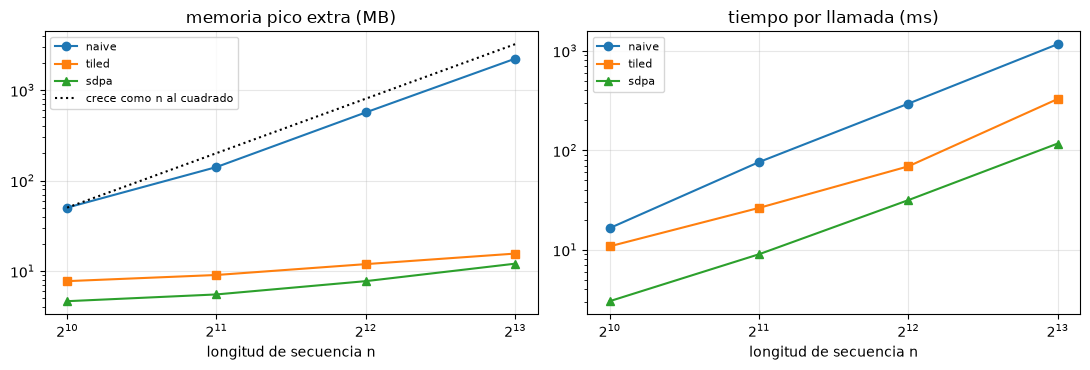

In [4]:
ATTN_SRC = '''
import math, torch, torch.nn.functional as F

def attn_naive(q, k, v, causal=True):
    # atención estándar: materializa la matriz completa de puntuaciones n x n
    s = (q @ k.transpose(-1, -2)) / math.sqrt(q.shape[-1])
    if causal:
        n = q.shape[-2]
        s = s.masked_fill(torch.triu(torch.ones(n, n, dtype=torch.bool), 1), float("-inf"))
    return s.softmax(-1) @ v

def attn_tiled(q, k, v, causal=True, bq=256, bk=256):
    # estilo FlashAttention: bucle sobre bloques de consultas y de claves con el softmax en línea; nunca construye n x n
    B, H, n, d = q.shape
    out = torch.empty_like(q)
    scale = 1.0 / math.sqrt(d)
    for i in range(0, n, bq):
        qi = q[:, :, i:i + bq]
        nq = qi.shape[-2]
        m = torch.full((B, H, nq), float("-inf"))        # máximo acumulado de las puntuaciones
        l = torch.zeros(B, H, nq)                        # normalizador acumulado
        o = torch.zeros(B, H, nq, d)                     # salida acumulada sin normalizar
        jmax = min(n, i + bq) if causal else n           # los bloques de claves enteros por encima de la diagonal se saltan
        for j in range(0, jmax, bk):
            kj, vj = k[:, :, j:j + bk], v[:, :, j:j + bk]
            s = (qi @ kj.transpose(-1, -2)) * scale
            if causal and j + bk > i:                    # el bloque toca la diagonal: se enmascara el futuro
                qpos = torch.arange(i, i + nq)[:, None]
                kpos = torch.arange(j, j + kj.shape[-2])[None, :]
                s = s.masked_fill(kpos > qpos, float("-inf"))
            m_new = torch.maximum(m, s.amax(-1))
            p = torch.exp(s - m_new[..., None])
            alpha = torch.exp(m - m_new)                 # reescala lo acumulado bajo el máximo anterior
            l = l * alpha + p.sum(-1)
            o = o * alpha[..., None] + p @ vj
            m = m_new
        out[:, :, i:i + bq] = o / l[..., None]
    return out

def attn_sdpa(q, k, v, causal=True):
    return F.scaled_dot_product_attention(q, k, v, is_causal=causal)
'''
with open(os.path.join(WORK, "attn_impl.py"), "w") as fh:
    fh.write(ATTN_SRC)
from attn_impl import attn_naive, attn_tiled, attn_sdpa

# comprobación de exactitud con datos aleatorios, con y sin máscara causal, y con tamaños que no son múltiplos del bloque
g = torch.Generator().manual_seed(0)
for n_chk, causal in [(1000, True), (1000, False), (512, True)]:
    q, k, v = (torch.randn(2, 4, n_chk, 64, generator=g) for _ in range(3))
    ref = attn_naive(q, k, v, causal)
    print(f"n = {n_chk:4d} causal = {str(causal):5s}  max |tiled - naive| = {(attn_tiled(q, k, v, causal) - ref).abs().max().item():.2e}   "
          f"max |sdpa - naive| = {(attn_sdpa(q, k, v, causal) - ref).abs().max().item():.2e}")

PROBE = '''
import sys, json, statistics, torch
sys.path.insert(0, sys.argv[1])
method, n, threads = sys.argv[2], int(sys.argv[3]), int(sys.argv[4])
torch.set_num_threads(threads); torch.manual_seed(0)
from attn_impl import attn_naive, attn_tiled, attn_sdpa
from memtools import measure_peak
fn = {"naive": attn_naive, "tiled": attn_tiled, "sdpa": attn_sdpa}[method]
q, k, v = (torch.randn(1, 4, n, 64) for _ in range(3))
fn(q[:, :, :64], k[:, :, :64], v[:, :, :64])                     # calentamiento con una entrada diminuta
runs = [measure_peak(lambda: fn(q, k, v)) for _ in range(3)]
print(json.dumps(dict(extra_mb=max(r[1] for r in runs), ms=1000 * statistics.median(r[0] for r in runs))))
'''
SIZES = [1024, 2048, 4096, 8192]
res = {m: [] for m in ["naive", "tiled", "sdpa"]}
t0 = time.time()
for m in res:
    for n in SIZES:
        res[m].append(json.loads(run_script("attn_probe.py", PROBE, m, n, NT)))
print(f"medido en {time.time() - t0:.0f} s; memoria pico extra (MB) además de las entradas, y tiempo por llamada (ms), 4 cabezas, tamaño de cabeza 64, causal")
print(f"{'n':>6s} | " + " | ".join(f"{m:>18s}" for m in res))
for i, n in enumerate(SIZES):
    print(f"{n:6d} | " + " | ".join(f"{res[m][i]['extra_mb']:8.0f} MB {res[m][i]['ms']:6.0f} ms" for m in res))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for m, st in [("naive", "o-"), ("tiled", "s-"), ("sdpa", "^-")]:
    ax[0].plot(SIZES, [max(r["extra_mb"], 0.5) for r in res[m]], st, label=m)
    ax[1].plot(SIZES, [r["ms"] for r in res[m]], st, label=m)
ax[0].plot(SIZES, [res["naive"][0]["extra_mb"] * (n / SIZES[0]) ** 2 for n in SIZES], "k:", label="crece como n al cuadrado")
for a_, t_ in zip(ax, ["memoria pico extra (MB)", "tiempo por llamada (ms)"]):
    a_.set_xscale("log", base=2); a_.set_yscale("log"); a_.set_xlabel("longitud de secuencia n"); a_.set_title(t_); a_.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Lectura.** La implementación por bloques reproduce la atención normal hasta el error de redondeo (diferencias por debajo de $10^{-6}$ en precisión simple, con atención causal y no causal y con longitudes que no son múltiplos del tamaño de bloque), así que FlashAttention es **exacta**, no una aproximación. La tabla de memoria muestra el sentido del método: la memoria extra de la implementación estándar crece con el cuadrado de $n$ (unas 16 veces más al pasar de $n = 2048$ a $8192$, hasta 2.2 GB con $n = 8192$ para solo 4 cabezas), mientras que la versión por bloques necesita solo unos megabytes más (de 7 a 16 MB, que es el tamaño de la propia salida, con crecimiento lineal) porque en cada momento solo existen bloques de $256 \times 256$ puntuaciones. El núcleo fusionado de la biblioteca es igual de ligero y es unas 2.5 veces más rápido que nuestro bucle de Python, que paga la sobrecarga del intérprete en cada bloque. A diferencia de una GPU, nuestro bucle por bloques es además unas 4 veces **más rápido** que la versión estándar en esta CPU, por una razón de la misma familia que la de FlashAttention: la versión estándar escribe y relee gigabytes de puntuaciones por la memoria principal, mientras que los bloques se quedan en la caché (la aceleración real de FlashAttention en GPU, por mantener los bloques en SRAM en lugar de HBM, es mayor y no se puede mostrar en Python). La consecuencia práctica es que el muro de memoria de los contextos largos desaparece, mientras que el muro aritmético se queda: la atención con 100 000 tokens sigue costando $10^{10}$ entradas de puntuación por cabeza y capa, lo que motiva las secciones sobre ventanas deslizantes y modelos de espacio de estados.

## 3. Atención multi-consulta y de consultas agrupadas

Durante la generación cada token nuevo necesita las claves y valores de **todos los tokens anteriores** en cada capa, guardados en la caché KV. Con contextos largos y lotes grandes esta caché, y no los pesos, domina la memoria, y leerla de la memoria en cada paso domina el tiempo (un paso de decodificación hace muy poca aritmética por byte leído, así que está limitado por el ancho de banda de memoria).

La **atención multicabeza** (MHA, multi-head attention) da a cada una de las $H$ cabezas de consulta su propia cabeza de clave y de valor. La **atención multi-consulta** (MQA, multi-query attention; Shazeer, 2019) comparte una *única* cabeza de clave/valor entre todas las cabezas de consulta: la caché se reduce $H$ veces, con cierta pérdida de calidad. La **atención de consultas agrupadas** (GQA, grouped-query attention; Ainslie et al., 2023) es el término medio: $n_\text{kv}$ cabezas de clave/valor, cada una compartida por un grupo de $H / n_\text{kv}$ cabezas de consulta. MHA es el caso $n_\text{kv} = H$ y MQA el caso $n_\text{kv} = 1$. Llama-2 70B, Llama-3 y Mistral 7B usan GQA.

Medimos tres cosas para $H = 16$ cabezas de consulta de tamaño 64: los bytes de la caché, el tiempo de un paso de decodificación que la lee y la calidad de un pequeño modelo de lenguaje entrenado con cada configuración. El paso de decodificación está escrito de forma que un grupo de cabezas de consulta se procesa como una sola matriz frente a su cabeza de clave/valor compartida, sin copiar las claves y los valores $H / n_\text{kv}$ veces.

In [5]:
def decode_attn(q, K, V):
    # un paso de decodificación. q: (B, H, dh) consultas del token nuevo; K, V: (B, Hkv, ctx, dh) la caché.
    # Las G = H / Hkv cabezas de consulta de un grupo se apilan como filas frente a su cabeza de clave/valor compartida (sin copiar K ni V).
    B, H, dh = q.shape; Hkv = K.shape[1]; G = H // Hkv
    s = (q.view(B, Hkv, G, dh) @ K.transpose(-1, -2)) / math.sqrt(dh)        # (B, Hkv, G, ctx)
    return (s.softmax(-1) @ V).reshape(B, H, dh)

# corrección frente a la versión que copia
B, H, dh, ctx = 2, 16, 64, 300
q = torch.randn(B, H, dh); K = torch.randn(B, 4, ctx, dh); V = torch.randn(B, 4, ctx, dh)
ref = (((q[:, :, None] @ K.repeat_interleave(4, 1).transpose(-1, -2)) / math.sqrt(dh)).softmax(-1) @ V.repeat_interleave(4, 1))[:, :, 0]
print("la decodificación agrupada coincide con la versión que copia: diferencia máx.", f"{(decode_attn(q, K, V) - ref).abs().max().item():.1e}")

B, H, dh, ctx, LAYERS = 8, 16, 64, 4096, 24
rows = []
for Hkv in [16, 8, 4, 2, 1]:
    K = torch.randn(B, Hkv, ctx, dh); V = torch.randn(B, Hkv, ctx, dh); q = torch.randn(B, H, dh)
    decode_attn(q, K, V)
    ts = []
    for _ in range(7):
        t = time.perf_counter(); decode_attn(q, K, V); ts.append(time.perf_counter() - t)
    layer_bytes = (K.numel() + V.numel()) * K.element_size()            # bytes que guarda realmente la caché de esta capa
    rows.append((Hkv, layer_bytes * LAYERS / 1e9, layer_bytes * LAYERS / 2 / 1e9, 1000 * statistics.median(ts)))
print(f"caché para un lote de {B} secuencias de {ctx} tokens, {LAYERS} capas, H = {H} cabezas de consulta de tamaño {dh}")
print(f"{'cabezas kv':>8s} {'caché fp32 (GB)':>16s} {'caché bf16 (GB)':>16s} {'una capa, un paso (ms)':>32s} {'vs MHA':>8s}")
for Hkv, g32, g16, ms in rows:
    print(f"{Hkv:8d} {g32:16.2f} {g16:16.2f} {ms:32.2f} {rows[0][3] / ms:7.1f}x")

la decodificación agrupada coincide con la versión que copia: diferencia máx. 3.6e-07


caché para un lote de 8 secuencias de 4096 tokens, 24 capas, H = 16 cabezas de consulta de tamaño 64
cabezas kv  caché fp32 (GB)  caché bf16 (GB)           una capa, un paso (ms)   vs MHA
      16             6.44             3.22                             6.41     1.0x
       8             3.22             1.61                             3.80     1.7x
       4             1.61             0.81                             2.34     2.7x
       2             0.81             0.40                             1.31     4.9x
       1             0.40             0.20                             0.94     6.8x


In [6]:
# calidad: el mismo modelo de lenguaje pequeño a nivel de carácter con 8 cabezas de consulta y 8, 2 o 1 cabezas de clave/valor
files = sorted(glob.glob(os.path.join(sysconfig.get_paths()["stdlib"], "*.py")))[:250]
text = "".join(open(f, encoding="utf-8", errors="ignore").read() for f in files)
data = torch.tensor(list(text.encode("ascii", "ignore")[:1_200_000]), dtype=torch.long)
cut = int(0.9 * len(data)); train_data, val_data = data[:cut], data[cut:]
print(f"corpus: código fuente de la biblioteca estándar de Python, {len(data):,} caracteres (licencia de la Python Software Foundation), {len(files)} archivos")

def get_batch(src, B, n, g):
    ix = torch.randint(0, len(src) - n - 1, (B,), generator=g)
    xb = torch.stack([src[i:i + n + 1] for i in ix])
    return xb[:, :-1], xb[:, 1:]

def train_lm(Hkv, steps=200, seed=0):
    torch.manual_seed(seed); g = torch.Generator().manual_seed(seed)
    m = TinyLM(V=128, d=128, L=3, H=8, Hkv=Hkv, n_max=96)
    opt = torch.optim.AdamW(m.parameters(), lr=3e-3, weight_decay=0.01)
    for t in range(steps):
        lr = 3e-3 * min(1, (t + 1) / 20) * (0.1 + 0.9 * 0.5 * (1 + math.cos(math.pi * t / steps)))
        for pg in opt.param_groups: pg["lr"] = lr
        xb, yb = get_batch(train_data, 32, 96, g)
        loss = F.cross_entropy(m(xb).reshape(-1, 128), yb.reshape(-1))
        opt.zero_grad(); loss.backward(); opt.step()
    m.eval(); gv = torch.Generator().manual_seed(123)
    with torch.no_grad():
        vl = np.mean([F.cross_entropy(m(xb).reshape(-1, 128), yb.reshape(-1)).item() for xb, yb in (get_batch(val_data, 64, 96, gv) for _ in range(10))])
    return vl, sum(p.numel() for p in m.parameters())

t0 = time.time()
print(f"{'cabezas kv':>8s} {'parámetros':>11s} {'pérdida val. (nats)':>16s} {'caché KV por token (bytes, fp32)':>34s}")
gqa_loss = {}
for Hkv in [8, 2, 1]:
    vl, npar = train_lm(Hkv)
    gqa_loss[Hkv] = vl
    print(f"{Hkv:8d} {npar:11,d} {vl:16.3f} {2 * 3 * Hkv * 16 * 4:34d}")
print(f"entrenado en {time.time() - t0:.0f} s")

corpus: código fuente de la biblioteca estándar de Python, 1,200,000 caracteres (licencia de la Python Software Foundation), 167 archivos
cabezas kv  parámetros pérdida val. (nats)   caché KV por token (bytes, fp32)


       8     636,672            2.250                               3072


       2     562,944            2.252                                768


       1     550,656            2.281                                384
entrenado en 57 s


**Lectura.** La caché medida en bytes baja en proporción exacta al número de cabezas de clave/valor: de 6.4 GB (números de 32 bits, MHA) a 0.4 GB con una sola cabeza, la reducción de 16 veces que predijo la calculadora de la sección 1. El paso de decodificación también es más rápido, porque lee menos bytes: unas 1.7 veces más rápido con 8 cabezas, 3 veces con 4 y de 6 a 7 veces con 2 o 1, menos de lo que dice el recuento de bytes porque la aritmética del softmax y de las consultas no disminuye; los tiempos vienen de una máquina compartida y fluctúan decenas de puntos porcentuales (por eso 2 y 1 cabezas no salen ordenadas aquí), y las razones exactas dependen del sistema de memoria. En una GPU que sirve muchas peticiones el efecto es mayor, porque la caché es lo principal que se lee en cada paso. La columna de calidad es una medición **débil**: 200 pasos de entrenamiento con una semilla. GQA con 2 cabezas de clave/valor (4 cabezas de consulta por grupo) igualó a la atención multicabeza completa hasta el tercer decimal (2.250 frente a 2.252 nats) guardando una cuarta parte de la caché, y una sola cabeza de clave/valor (MQA) fue 0.03 nats peor; con una semilla no podemos decir si 0.03 es más que la variación entre semillas. Los artículos describen una pérdida de calidad pequeña pero real en MQA que GQA con 4 a 8 grupos elimina en su mayor parte, a gran escala y tras entrenamientos largos; por eso los modelos de producción eligen un valor intermedio de $n_\text{kv}$.

## 4. Contexto largo: RoPE y ventanas deslizantes

La atención por sí sola no tiene noción de orden. Los modelos añaden **información de posición**. El transformer original sumaba un vector por posición a la entrada; la mayoría de los modelos abiertos recientes usan **embeddings de posición rotatorios** (RoPE; Su et al., 2021, el artículo de RoFormer). RoPE no suma nada: **rota** los vectores de consulta y de clave en un ángulo que crece con su posición $m$. Se divide un vector en pares de coordenadas $(x_{2i}, x_{2i+1})$ y se rota el par $i$ en el ángulo $m\,\theta_i$ con $\theta_i = 10\,000^{-2i/d_\text{head}}$ (frecuencias bajas en los pares posteriores, de modo que unos pares giran rápido y otros muy despacio). La propiedad clave es que el producto escalar de una consulta rotada en la posición $m$ y una clave rotada en la posición $n$ es igual al producto escalar de los vectores sin rotar rotados por el ángulo $(m - n)\,\theta_i$: la puntuación de atención depende solo de la distancia **relativa** $m - n$, sin una tabla aprendida de posiciones que se acabaría en la longitud de entrenamiento. Lo comprobamos numéricamente.

Una segunda herramienta para entradas largas es la **atención de ventana deslizante**: cada token atiende solo a los $w$ tokens anteriores, de modo que el coste es $O(n\,w)$ en lugar de $O(n^2)$ y la caché KV necesita solo $w$ entradas (un búfer rotatorio). La información sigue viajando más lejos que $w$ tokens, porque la capa $\ell$ ve lo que la capa $\ell - 1$ vio en cada posición de su ventana: tras $L$ capas el alcance es de $L\,(w - 1) + 1$ tokens (Mistral 7B usa $w = 4096$ con 32 capas; Jiang et al., 2023). Medimos este alcance directamente con diferenciación automática.

puntuación entre q en la posición m y k en la posición m - desplazamiento, para varias posiciones absolutas m:
  desplazamiento    0:   7.38240    7.38240    7.38240    7.38240   dispersión 1.8e-15
  desplazamiento    1:   4.94841    4.94841    4.94841    4.94841   dispersión 3.6e-12
  desplazamiento    5:   9.59312    9.59312    9.59312    9.59312   dispersión 7.7e-12
  desplazamiento   50:  14.52925   14.52925   14.52925   14.52925   dispersión 6.6e-12
  desplazamiento  500:  11.51229   11.51229   11.51229   11.51229   dispersión 6.3e-12
sin RoPE la puntuación no dependería de la posición; con RoPE depende solo del desplazamiento.



ventana w = 16: token más lejano que influye en la última posición
  1 capa(s): alcance medido  16 tokens, fórmula L (w - 1) + 1 = 16
  2 capa(s): alcance medido  31 tokens, fórmula L (w - 1) + 1 = 31
  3 capa(s): alcance medido  46 tokens, fórmula L (w - 1) + 1 = 46
  4 capa(s): alcance medido  61 tokens, fórmula L (w - 1) + 1 = 61
  5 capa(s): alcance medido  76 tokens, fórmula L (w - 1) + 1 = 76
  6 capa(s): alcance medido  91 tokens, fórmula L (w - 1) + 1 = 91


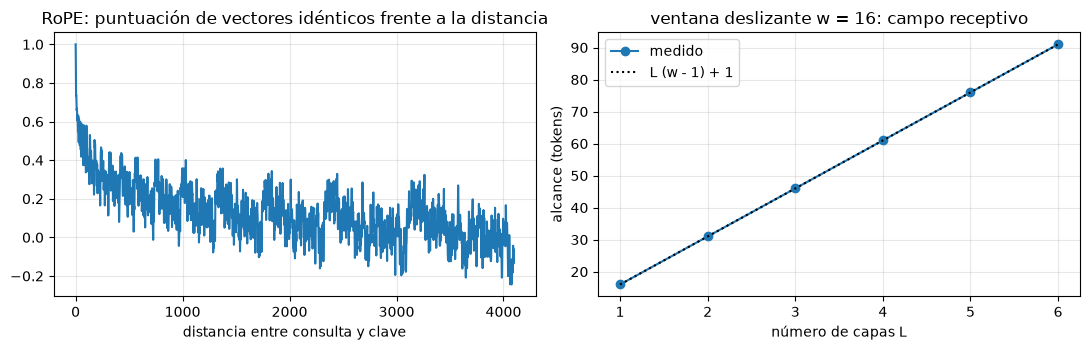

In [7]:
def rope(x, pos, base=10000.0):
    # rota los pares de coordenadas (x_2i, x_2i+1) de x (..., n, dh) en el ángulo pos * theta_i
    dh = x.shape[-1]
    theta = base ** (-torch.arange(0, dh, 2, dtype=x.dtype) / dh)
    ang = pos[:, None].to(x.dtype) * theta[None, :]
    cos, sin = ang.cos(), ang.sin()
    out = torch.empty_like(x)
    out[..., 0::2] = x[..., 0::2] * cos - x[..., 1::2] * sin
    out[..., 1::2] = x[..., 0::2] * sin + x[..., 1::2] * cos
    return out

torch.manual_seed(0)
dh = 64
q0, k0 = torch.randn(dh, dtype=torch.float64), torch.randn(dh, dtype=torch.float64)
offsets = [0, 1, 5, 50, 500]
print("puntuación entre q en la posición m y k en la posición m - desplazamiento, para varias posiciones absolutas m:")
for off in offsets:
    scores = []
    for m in [off, off + 10, off + 1000, off + 100000]:
        qm = rope(q0[None], torch.tensor([m]))[0]; kn = rope(k0[None], torch.tensor([m - off]))[0]
        scores.append((qm @ kn).item())
    print(f"  desplazamiento {off:4d}: " + "  ".join(f"{s:9.5f}" for s in scores) + f"   dispersión {max(scores) - min(scores):.1e}")
print("sin RoPE la puntuación no dependería de la posición; con RoPE depende solo del desplazamiento.")

# el mismo vector en cada posición: cómo decae la puntuación con la distancia (el decaimiento de largo alcance propio de RoPE)
dist = torch.arange(0, 4096)
ones = torch.ones(dh, dtype=torch.float64)
dec = torch.stack([(rope(ones[None], torch.tensor([0]))[0] @ rope(ones[None], torch.tensor([int(dd)]))[0]) for dd in dist]) / dh

# campo receptivo de capas apiladas de atención de ventana deslizante, medido con gradientes
def window_layer(x, w, Wq, Wk, Wv):
    n = x.shape[0]
    s = (x @ Wq) @ (x @ Wk).T / math.sqrt(x.shape[1])
    i, j = torch.arange(n)[:, None], torch.arange(n)[None, :]
    s = s.masked_fill((j > i) | (j <= i - w), float("-inf"))              # causal y dentro de los últimos w tokens
    return s.softmax(-1) @ (x @ Wv)

n, w, d = 200, 16, 8
torch.manual_seed(0)
Ws = [[torch.randn(d, d, dtype=torch.float64) / math.sqrt(d) for _ in range(3)] for _ in range(6)]
reach = []
for depth in range(1, 7):
    x = torch.randn(n, d, dtype=torch.float64, requires_grad=True)
    h = x
    for l_ in range(depth):
        h = window_layer(h, w, *Ws[l_])
    h[-1].sum().backward()
    nz = (x.grad.abs().sum(-1) > 0).nonzero().flatten()
    reach.append(n - nz.min().item())
print("\nventana w = 16: token más lejano que influye en la última posición")
for depth, r in enumerate(reach, 1):
    print(f"  {depth} capa(s): alcance medido {r:3d} tokens, fórmula L (w - 1) + 1 = {depth * (w - 1) + 1}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(dist.numpy(), dec.numpy()); ax[0].set_xlabel("distancia entre consulta y clave"); ax[0].set_title("RoPE: puntuación de vectores idénticos frente a la distancia")
ax[1].plot(range(1, 7), reach, "o-", label="medido"); ax[1].plot(range(1, 7), [d_ * (w - 1) + 1 for d_ in range(1, 7)], "k:", label="L (w - 1) + 1")
ax[1].set_xlabel("número de capas L"); ax[1].set_ylabel("alcance (tokens)"); ax[1].set_title("ventana deslizante w = 16: campo receptivo"); ax[1].legend()
plt.tight_layout(); plt.show()

**Lectura.** Con RoPE la puntuación entre una consulta y una clave depende solo de su desplazamiento: para cada desplazamiento las puntuaciones calculadas en posiciones absolutas de 0 a 100 000 coinciden hasta unos $10^{-11}$ (redondeo), así que el modelo no tiene posiciones absolutas que se le acaben, y la curva muestra la tendencia propia de RoPE a que vectores idénticos se descorrelacionen con la distancia. Por eso los modelos con RoPE se pueden extender más allá de su longitud de entrenamiento reescalando las posiciones (interpolación de posiciones, Chen et al., 2023, [arXiv:2306.15595](https://arxiv.org/abs/2306.15595)), aunque la calidad con longitudes nunca vistas en el entrenamiento sigue necesitando ajuste fino. Con las ventanas deslizantes el alcance medido coincide exactamente con la fórmula $L\,(w-1)+1$ en cada profundidad, de modo que apilar capas sí amplía el alcance de forma lineal, mientras que cada capa y la caché KV siguen acotadas por $w$. El límite es que la información lejana tiene que pasar a través de tokens intermedios y se desvanece, así que un dato del comienzo de un documento muy largo no está disponible de forma fiable al final; es el compromiso que la atención completa (cara) y los modelos de espacio de estados (sección 6) abordan desde lados opuestos.

## 5. Mezcla de expertos

En un transformer denso cada token pasa por todos los parámetros. Una **mezcla de expertos** (MoE; Shazeer et al., 2017, de activación dispersa; Fedus et al., 2021, Switch Transformer) sustituye el bloque feed-forward de una capa por $E$ bloques feed-forward paralelos, los **expertos**, y un **enrutador** pequeño que elige, para cada token, solo los $k$ mejores. El modelo tiene $E$ veces los parámetros feed-forward (más **capacidad**, más conocimiento almacenado) pero cada token paga la aritmética de solo $k$ expertos (los parámetros **activos**). Para un token con vector oculto $x$:

$$\text{logits} = W_r\, x \in \mathbb{R}^E, \quad p = \operatorname{softmax}(\text{logits}), \quad \text{TopK} = \text{los } k \text{ mayores } p_i, \quad y = \sum_{i \in \text{TopK}} p_i\, \text{Expert}_i(x),$$

donde $W_r$ es la matriz de pesos del enrutador. (Hay variantes que renormalizan los $k$ pesos elegidos para que sumen uno; para $k = 1$ hay que conservar $p_i$ tal cual, porque si no el enrutador no recibiría gradiente de la tarea.)

**Balance de carga.** Si se le deja solo, el enrutador tiende a colapsar: un experto que es algo mejor al principio recibe más tokens, entrena más, mejora aún más y los demás se mueren de hambre ("el rico se hace más rico"). Los expertos muertos desperdician parámetros, y en hardware real un experto sobrecargado se vuelve un cuello de botella. El remedio estándar es una **pérdida auxiliar** que se suma a la pérdida de entrenamiento. Con $f_i$ la fracción de tokens enviados al experto $i$ y $P_i$ la probabilidad media $p_i$ del enrutador en el lote,

$$\mathcal{L}_\text{aux} = E \sum_{i=1}^{E} f_i\, P_i,$$

que es mínima ($=1$) cuando ambas son uniformes; se multiplica por un coeficiente pequeño $\alpha$ (0.01 en Switch Transformer). La construimos sobre una tarea diseñada para exigir especialización: ocho grupos de entradas en 16 dimensiones, cada grupo con su propia función objetivo aleatoria. Una red densa tiene que aprender las ocho funciones con unidades ocultas compartidas; un MoE puede dar a cada grupo su propio experto, si su enrutador encuentra los grupos. El juguete está hecho para favorecer al MoE, así que lee sus ventajas como el mejor caso.

varianza del objetivo 0.233; error cuadrático medio de prueba, media de 2 semillas
  denso, oculto   4: parámetros activos = totales    88   MSE 0.1983
  denso, oculto   8: parámetros activos = totales   172   MSE 0.1694
  denso, oculto  16: parámetros activos = totales   340   MSE 0.1092
  denso, oculto  32: parámetros activos = totales   676   MSE 0.0507
  denso, oculto  64: parámetros activos = totales  1348   MSE 0.0268
  denso, oculto 128: parámetros activos = totales  2692   MSE 0.0213
  MoE 8 expertos top-1: activos   468   totales  2848   MSE 0.0182
  MoE 8 expertos top-2: activos   808   totales  2848   MSE 0.0171
  MoE 8 expertos top-4: activos  1488   totales  2848   MSE 0.0189


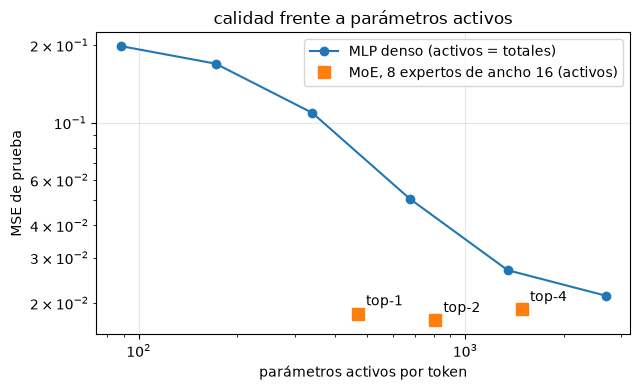

21 s


In [8]:
K_CL, D_IN, D_OUT = 8, 16, 4
g = torch.Generator().manual_seed(0)
centers = torch.randn(K_CL, D_IN, generator=g) * 2.0
W1t = torch.randn(K_CL, D_IN, 16, generator=g) / D_IN ** 0.5 * 1.5
W2t = torch.randn(K_CL, 16, D_OUT, generator=g) / 4

def make_data(n, seed):
    gg = torch.Generator().manual_seed(seed)
    c = torch.randint(0, K_CL, (n,), generator=gg)
    x = centers[c] + 0.5 * torch.randn(n, D_IN, generator=gg)
    y = torch.einsum("nh,nho->no", torch.tanh(torch.einsum("nd,ndh->nh", x - centers[c], W1t[c])), W2t[c])   # cada grupo tiene su propia función
    return x, y
Xtr, Ytr = make_data(8192, 1); Xte, Yte = make_data(4096, 2)

class DenseMLP(nn.Module):
    def __init__(self, h):
        super().__init__(); self.net = nn.Sequential(nn.Linear(D_IN, h), nn.GELU(), nn.Linear(h, D_OUT))
    def forward(self, x): return self.net(x), None, None

class MoE(nn.Module):
    # E expertos de tamaño oculto h; cada token se envía a sus k mejores expertos, ponderado por la probabilidad del enrutador
    def __init__(self, E=8, h=16, k=1):
        super().__init__(); self.E, self.k = E, k
        self.router = nn.Linear(D_IN, E, bias=False)
        self.w1 = nn.Parameter(torch.randn(E, D_IN, h) / D_IN ** 0.5); self.b1 = nn.Parameter(torch.zeros(E, 1, h))
        self.w2 = nn.Parameter(torch.randn(E, h, D_OUT) / h ** 0.5); self.b2 = nn.Parameter(torch.zeros(E, 1, D_OUT))
    def forward(self, x):
        probs = self.router(x).softmax(-1)
        _, idx = probs.topk(self.k, -1); gate = probs.gather(1, idx)             # expertos elegidos y sus pesos
        out = torch.zeros(x.shape[0], D_OUT)
        for e in range(self.E):
            rows, slot = (idx == e).nonzero(as_tuple=True)
            if rows.numel():
                hid = F.gelu(x[rows] @ self.w1[e] + self.b1[e])
                out.index_add_(0, rows, gate[rows, slot, None] * (hid @ self.w2[e] + self.b2[e]))
        f = torch.zeros(self.E).index_add_(0, idx.reshape(-1), torch.ones(idx.numel())) / idx.numel()   # fracción de asignaciones por experto
        aux = self.E * (f * probs.mean(0)).sum()
        return out, aux, f

def fit(model, steps=1000, aux_w=0.0, seed=0):
    torch.manual_seed(seed); opt = torch.optim.Adam(model.parameters(), 3e-3)
    for t in range(steps):
        i = torch.randint(0, len(Xtr), (256,))
        out, aux, _ = model(Xtr[i])
        loss = F.mse_loss(out, Ytr[i]) + (aux_w * aux if aux is not None else 0.0)
        opt.zero_grad(); loss.backward(); opt.step()
    with torch.no_grad():
        out, _, f = model(Xte)
    return F.mse_loss(out, Yte).item(), f

npar = lambda m: sum(p.numel() for p in m.parameters())
t0 = time.time()
dense_res = {}
for h in [4, 8, 16, 32, 64, 128]:
    runs = [fit(DenseMLP(h), seed=s)[0] for s in (0, 1)]
    dense_res[h] = (npar(DenseMLP(h)), float(np.mean(runs)))
moe_res = {}
for k in [1, 2, 4]:
    runs = [fit(MoE(k=k), aux_w=0.01, seed=s)[0] for s in (0, 1)]
    m_ = MoE(k=k); active = npar(m_.router) + k * (D_IN * 16 + 16 + 16 * D_OUT + D_OUT)
    moe_res[k] = (active, npar(m_), float(np.mean(runs)))
print(f"varianza del objetivo {Yte.var().item():.3f}; error cuadrático medio de prueba, media de 2 semillas")
for h, (n_, e_) in dense_res.items():
    print(f"  denso, oculto {h:3d}: parámetros activos = totales {n_:5d}   MSE {e_:.4f}")
for k, (a_, t_, e_) in moe_res.items():
    print(f"  MoE 8 expertos top-{k}: activos {a_:5d}   totales {t_:5d}   MSE {e_:.4f}")

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot([v[0] for v in dense_res.values()], [v[1] for v in dense_res.values()], "o-", label="MLP denso (activos = totales)")
ax.plot([v[0] for v in moe_res.values()], [v[2] for v in moe_res.values()], "s", ms=9, label="MoE, 8 expertos de ancho 16 (activos)")
for k, (a_, t_, e_) in moe_res.items(): ax.annotate(f"top-{k}", (a_, e_), textcoords="offset points", xytext=(6, 6))
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("parámetros activos por token"); ax.set_ylabel("MSE de prueba"); ax.legend(); ax.set_title("calidad frente a parámetros activos")
plt.tight_layout(); plt.show()
print(f"{time.time() - t0:.0f} s")

**Lectura.** Por parámetro activo el MoE va muy por delante en esta tarea: el modelo top-1, que usa 468 parámetros por token, alcanza un error de prueba de 0.018, menor que el de la mejor red densa (2692 parámetros, todos usados en cada token, error 0.021), y top-2 (0.017) y top-4 (0.019) no añaden nada visible. Una red densa de 676 parámetros es unas 2.8 veces peor (0.051), porque tiene que repartir sus unidades ocultas entre ocho funciones distintas. Esta es la promesa del MoE: **la capacidad crece con el número total de parámetros, el coste con los activos**. No es gratis: el modelo guarda en memoria $E$ veces los parámetros feed-forward (aquí 2848 frente a 468 activos, 6 veces más), de modo que el MoE ahorra aritmética y no memoria, y en el entrenamiento distribuido los tokens deben intercambiarse entre los dispositivos que guardan los expertos. Además la tarea se eligió para que los grupos sean fáciles de encontrar para un enrutador; en lenguaje, los expertos se especializan de forma mucho más difusa (mira el modelo real más abajo). Dos semillas por punto es poca evidencia; la diferencia entre el MoE y las redes densas pequeñas es mucho mayor que el cambio entre semillas, pero el orden entre top-1, top-2 y top-4 no queda resuelto.

Ahora el modo de fallo. Entrenamos el MoE top-1 sin balance, con $\alpha = 0.01$ y con $\alpha = 0.1$ en tres semillas, y miramos cómo se reparten los tokens entre los 8 expertos (los grupos son igual de frecuentes, así que un enrutador ideal usa cada experto para el 12.5 % de los tokens).

 peso aux.            MSE por semilla expertos muertos (<1 % de tokens)  cuota del más ocupado
      0.00     [0.0177 0.0181 0.0186]                        [1, 3, 3]     [0.26, 0.26, 0.38]
      0.01     [0.0207 0.0205 0.0172]                        [3, 3, 2]     [0.25, 0.26, 0.25]
      0.10     [0.0163 0.0158 0.0162]                        [0, 0, 0]     [0.13, 0.13, 0.13]


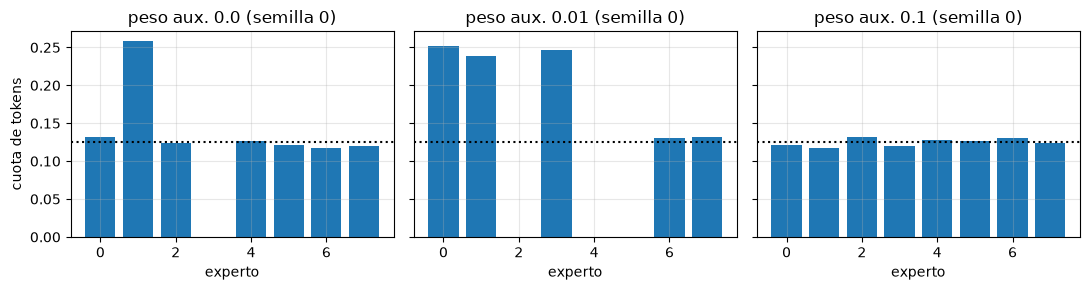

19 s


In [9]:
t0 = time.time()
coll = {}
for aux_w in [0.0, 0.01, 0.1]:
    mses, usage = [], []
    for s in (0, 1, 2):
        mse, f = fit(MoE(k=1), aux_w=aux_w, seed=s)
        mses.append(mse); usage.append(f.numpy())
    coll[aux_w] = (mses, usage)
print(f"{'peso aux.':>10s} {'MSE por semilla':>26s} {'expertos muertos (<1 % de tokens)':>32s} {'cuota del más ocupado':>22s}")
for aux_w, (mses, usage) in coll.items():
    print(f"{aux_w:10.2f} {str(np.round(mses, 4)):>26s} {str([int((u < 0.01).sum()) for u in usage]):>32s} {str([round(float(u.max()), 2) for u in usage]):>22s}")

fig, ax = plt.subplots(1, 3, figsize=(11, 3), sharey=True)
for a_, (aux_w, (mses, usage)) in zip(ax, coll.items()):
    a_.bar(range(8), usage[0], color="tab:blue"); a_.axhline(1 / 8, color="k", ls=":")
    a_.set_title(f"peso aux. {aux_w} (semilla 0)"); a_.set_xlabel("experto")
ax[0].set_ylabel("cuota de tokens")
plt.tight_layout(); plt.show()
print(f"{time.time() - t0:.0f} s")

**Lectura.** Sin la pérdida de balance el enrutamiento queda desequilibrado en todas las semillas: entre 1 y 3 de los 8 expertos casi no reciben tokens (muertos) y el más ocupado se lleva del 26 al 38 % de ellos en lugar del 12.5 %, de modo que los grupos se funden por parejas y el modelo usa menos expertos de los que tiene. Aquí el daño en el error es modesto (0.018), porque un experto de ancho 16 puede seguir atendiendo dos de estos grupos fáciles, pero los parámetros de los expertos muertos se desperdician, y en un clúster real el experto más ocupado marcaría la velocidad de toda la capa. El coeficiente habitual $\alpha = 0.01$ **no** lo arregló en este juguete (2 a 3 expertos muertos en las tres semillas): su gradiente es pequeño al lado de la pérdida de la tarea, y los expertos que han muerto siguen muertos. Con $\alpha = 0.1$ todas las semillas llegaron a una carga pareja (13 % para el más ocupado) y al mejor error (0.016, frente a 0.018 sin la pérdida), porque dejar que cada experto se especialice en un grupo es mejor aquí que compartir. Un coeficiente demasiado grande empuja hacia un reparto uniforme aunque los datos no lo sean, a costa de calidad, así que los sistemas reales lo ajustan (0.01 en Switch Transformer, 0.001 en el modelo de abajo) y añaden límites de capacidad por experto. Como en otras partes, tres semillas son una muestra pequeña: el patrón (desequilibrio sin la pérdida, equilibrio con una suficientemente grande) es claro, los recuentos exactos no.

**Un MoE real pequeño.** `ibm-granite/granite-3.0-1b-a400m-base` ([ficha del modelo](https://huggingface.co/ibm-granite/granite-3.0-1b-a400m-base), licencia Apache 2.0; equipo IBM Granite, 2024) tiene 24 capas, 32 expertos por capa y envía cada token a los 8 mejores. Lo ejecutamos sobre textos cortos de cuatro dominios y leemos las elecciones del enrutador, para ver cuántos parámetros usa realmente un token, qué tan parejo es el reparto de carga entre expertos y si tipos de texto distintos usan expertos distintos. La ficha lo describe como un modelo base para investigación y ajuste fino posterior, sin ajuste de seguridad; nosotros solo leemos su enrutamiento interno.

Loading weights:   0%|          | 0/219 [00:00<?, ?it/s]

Loading weights:  79%|███████▉  | 174/219 [00:00<00:00, 1714.69it/s]

Loading weights: 100%|██████████| 219/219 [00:00<00:00, 1822.61it/s]

cargado en 1 s: 1.33 miles de millones de parámetros en total, de ellos 1.21 miles de millones en 32 expertos x 24 capas
cada token usa 8 de 32 expertos por capa: unos 0.43 miles de millones de parámetros activos (32% del total); pesos en bf16: 2.7 GB


  code      180 tokens


  english   198 tokens


  spanish   224 tokens


  math      242 tokens

divergencia de Jensen-Shannon media entre perfiles de uso de expertos (bits, promedio de las 24 capas; 0 = igual, 1 = disjuntos):
  mismo dominio, primera mitad frente a segunda mitad del texto (suelo de ruido): 0.016
  code     frente a english : 0.166
  code     frente a spanish : 0.203
  code     frente a math    : 0.053
  english  frente a spanish : 0.055
  english  frente a math    : 0.125
  spanish  frente a math    : 0.161

desequilibrio de carga (cuota del experto más ocupado respecto a un reparto perfecto 1/32), promedio de capas: 2.63x, peor capa 4.00x; expertos nunca elegidos en alguna capa: 0 de 768


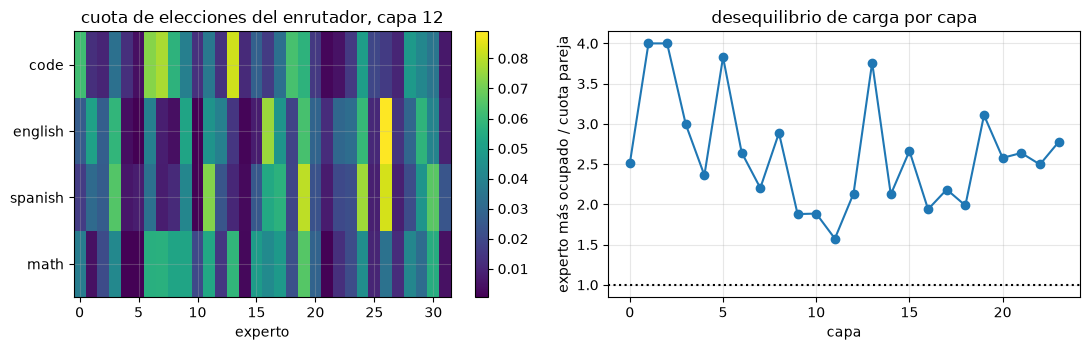

In [10]:
from transformers import AutoTokenizer, AutoModelForCausalLM
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error()

TEXTS = {
    "code": '''def moving_average(values, window):
    total = 0.0
    result = []
    for index, value in enumerate(values):
        total += value
        if index >= window:
            total -= values[index - window]
        if index >= window - 1:
            result.append(total / window)
    return result

class Stack:
    def __init__(self):
        self.items = []
    def push(self, item):
        self.items.append(item)
    def pop(self):
        if not self.items:
            raise IndexError("pop from empty stack")
        return self.items.pop()
    def __len__(self):
        return len(self.items)

for number in range(10):
    if number % 2 == 0:
        print(number, "is even")
''',
    "english": '''The harbour town sat at the mouth of a wide river, and for centuries its fortune had depended on the tide. In the morning the fishing boats left in a long line, and by afternoon the market filled with the smell of salt and smoke. Traders from the interior arrived with grain and wool, bargaining loudly with merchants who had learned to read the weather in the sky. When the railway came, many predicted that the old port would fade, but the town adapted: the warehouses became workshops, the quays became promenades, and the children of the sailors learned to repair machines instead of nets. Visitors today often remark on how calm the place feels, unaware that its calm is the result of generations of patient work and a long habit of looking at the horizon before deciding what to do next.
''',
    "spanish": '''El pueblo estaba junto a un río ancho y tranquilo, y durante siglos su vida dependió de las estaciones. Por la mañana los agricultores salian con sus carros hacia los campos, y por la tarde la plaza se llenaba de voces y del olor del pan recien hecho. Los comerciantes llegaban de las ciudades vecinas con telas, herramientas y noticias, y se sentaban a conversar durante horas bajo los arboles. Cuando se construyó la carretera, muchos pensaron que el pueblo quedaría olvidado, pero sus habitantes supieron adaptarse: abrieron pequeños talleres, restauraron las casas antiguas y aprendieron a recibir a los visitantes sin perder las costumbres que les daban identidad y orgullo.
''',
    "math": '''Let f be a continuous function on the closed interval [a, b]. Then f attains a maximum and a minimum on [a, b]. Suppose that f is differentiable on the open interval (a, b) and that f(a) = f(b). By Rolle's theorem there exists a point c in (a, b) such that the derivative f'(c) = 0. Consider the function g(x) = x^2 - 3x + 2 on the interval [0, 3]. Its derivative is g'(x) = 2x - 3, which vanishes at x = 3/2, and g(3/2) = -1/4 is the minimum value. For a sequence of real numbers a_n that converges to a limit L, for every epsilon greater than zero there is an integer N such that |a_n - L| < epsilon whenever n > N. The sum of the first n integers is n(n + 1)/2, and the sum of the first n squares is n(n + 1)(2n + 1)/6.
''',
}

GRANITE = "ibm-granite/granite-3.0-1b-a400m-base"
granite_ok = False
try:
    t0 = time.time()
    tok_g = AutoTokenizer.from_pretrained(GRANITE)
    mdl_g = AutoModelForCausalLM.from_pretrained(GRANITE, torch_dtype=torch.bfloat16).eval()
    granite_ok = True
except Exception as e:
    print("No se pudo cargar el modelo (¿sin red o sin transformers?):", repr(e)[:200])

if granite_ok:
    cfg = mdl_g.config
    total = sum(p.numel() for p in mdl_g.parameters())
    experts = sum(p.numel() for nme, p in mdl_g.named_parameters() if ".experts." in nme)
    E, TOPK = cfg.num_local_experts, cfg.num_experts_per_tok
    active = total - experts * (1 - TOPK / E)
    print(f"cargado en {time.time() - t0:.0f} s: {total/1e9:.2f} miles de millones de parámetros en total, de ellos {experts/1e9:.2f} miles de millones en {E} expertos x {cfg.num_hidden_layers} capas")
    print(f"cada token usa {TOPK} de {E} expertos por capa: unos {active/1e9:.2f} miles de millones de parámetros activos ({active/total:.0%} del total); pesos en bf16: {2*total/1e9:.1f} GB")
    usage = {}                                           # dominio -> (capas, expertos) cuota de las elecciones del enrutador
    halves = {}                                          # dominio -> uso en la primera y en la segunda mitad del texto
    for dom, txt in TEXTS.items():
        ids = tok_g(txt, return_tensors="pt")
        with torch.no_grad():
            rl = mdl_g(**ids, output_router_logits=True).router_logits          # tupla sobre capas de (tokens, E)
        n_tok = rl[0].shape[0]
        def share(sel):
            u = torch.zeros(len(rl), E)
            for li, r in enumerate(rl):
                top = r[sel].float().topk(TOPK, -1).indices.reshape(-1)
                u[li] = torch.bincount(top, minlength=E).float() / top.numel()
            return u
        usage[dom] = share(slice(None)); halves[dom] = (share(slice(0, n_tok // 2)), share(slice(n_tok // 2, None)))
        print(f"  {dom:8s} {n_tok:4d} tokens")

    def js(p, q):                                         # divergencia de Jensen-Shannon en bits, por capa
        m_ = (p + q) / 2
        kl = lambda a, b: (a * (a.clamp_min(1e-12) / b.clamp_min(1e-12)).log2()).sum(-1)
        return 0.5 * kl(p, m_) + 0.5 * kl(q, m_)
    within = np.mean([js(*halves[d_]).mean().item() for d_ in TEXTS])
    print(f"\ndivergencia de Jensen-Shannon media entre perfiles de uso de expertos (bits, promedio de las {cfg.num_hidden_layers} capas; 0 = igual, 1 = disjuntos):")
    print(f"  mismo dominio, primera mitad frente a segunda mitad del texto (suelo de ruido): {within:.3f}")
    names = list(TEXTS)
    for i in range(len(names)):
        for j in range(i + 1, len(names)):
            print(f"  {names[i]:8s} frente a {names[j]:8s}: {js(usage[names[i]], usage[names[j]]).mean().item():.3f}")
    allu = torch.stack(list(usage.values())).mean(0)
    imb = (allu.max(-1).values * E)
    print(f"\ndesequilibrio de carga (cuota del experto más ocupado respecto a un reparto perfecto 1/{E}), promedio de capas: {imb.mean().item():.2f}x, "
          f"peor capa {imb.max().item():.2f}x; expertos nunca elegidos en alguna capa: {int((allu == 0).sum())} de {allu.numel()}")

    fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
    layer = cfg.num_hidden_layers // 2
    im = ax[0].imshow(torch.stack([usage[d_][layer] for d_ in names]).numpy(), aspect="auto", cmap="viridis")
    ax[0].set_yticks(range(len(names))); ax[0].set_yticklabels(names); ax[0].set_xlabel("experto"); ax[0].set_title(f"cuota de elecciones del enrutador, capa {layer}")
    plt.colorbar(im, ax=ax[0])
    ax[1].plot(range(cfg.num_hidden_layers), imb.numpy(), "o-"); ax[1].axhline(1, color="k", ls=":")
    ax[1].set_xlabel("capa"); ax[1].set_ylabel("experto más ocupado / cuota pareja"); ax[1].set_title("desequilibrio de carga por capa")
    plt.tight_layout(); plt.show()
    del mdl_g

**Lectura.** El modelo real confirma la economía: se guardan 1330 millones de parámetros (1210 millones de ellos en expertos) pero solo unos 430 millones, el 32 %, se usan por token (el "a400m" de su nombre significa 400 millones activos), de modo que cuesta en aritmética más o menos lo que un modelo denso de 400 millones mientras guarda el conocimiento de uno mayor, y aun así necesita la memoria del conjunto (2.7 GB en bf16). El enrutamiento no es parejo: promediando las 24 capas el experto más ocupado recibe 2.6 veces su parte justa, y 4.0 veces en la peor capa, aunque el modelo se entrenó con una pérdida de balance, porque los datos reales no son uniformes; ningún experto queda sin usar en ninguna capa. El efecto del dominio es medible pero moderado: textos de dominios distintos usan mezclas de expertos distintas, con una divergencia entre dominios de 0.05 a 0.20 bits frente a un suelo de ruido de 0.016 dado por dos mitades del mismo texto. El patrón es por tipo de texto más que por tema: los pasajes de código y de matemáticas (ambos llenos de símbolos) tienen perfiles parecidos (0.053), igual que la prosa en inglés y en español (0.055), y las mayores distancias están entre el código y los textos en lenguaje natural (0.17 a 0.20). Esto coincide con los análisis publicados de modelos de lenguaje MoE, donde los expertos se especializan más por sintaxis y tipo de token que por tema. Con cuatro textos escritos a mano de 180 a 240 tokens esto es una ilustración, no un estudio.

## 6. Modelos de espacio de estados: S4 y Mamba

La atención conserva cada token pasado y los mira todos: recuerdo perfecto, coste $O(n^2)$ en el entrenamiento y una caché que crece con $n$. Un **modelo de espacio de estados** (SSM, state space model) en cambio mantiene un **estado** $h$ de tamaño fijo que resume el pasado y lo actualiza con cada token, como una red recurrente, pero con una actualización lineal que se puede calcular en paralelo. En tiempo continuo, $h'(t) = A\,h(t) + B\,x(t)$ y $y(t) = C\,h(t)$, con un estado de tamaño $N$ y matrices $A$, $B$, $C$. Al discretizar con un paso de tiempo $\Delta$ (retención de orden cero) se obtiene la recurrencia

$$h_t = a_t \odot h_{t-1} + b_t, \qquad a_t = e^{\Delta A}, \quad b_t \approx \Delta\,B\,x_t, \qquad y_t = C\,h_t,$$

donde, para una $A$ diagonal, todo actúa coordenada a coordenada ($\odot$ es el producto elemento a elemento). Desenrollándola se obtiene $h_t = \sum_{s \le t} \big(\prod_{r=s+1}^{t} a_r\big)\, b_s$: cada entrada pasada se suma con un peso que decae geométricamente con su antigüedad. Hay dos maneras de calcularla:

* **S4** (Gu et al., 2021, "structured state spaces", espacios de estados estructurados) mantiene $A$, $B$, $C$, $\Delta$ **constantes en el tiempo** (el modelo es lineal e invariante en el tiempo, LTI, linear time-invariant). Entonces la salida es una convolución de la entrada con un núcleo fijo $K_k = C\,\bar A^{k}\,\bar B$, calculada con la transformada rápida de Fourier en $O(n \log n)$ durante el entrenamiento, y como recurrencia con memoria constante durante la generación. La estructura especial de $A$ (derivada de la teoría HiPPO de la memoria óptima) le permite recordar secuencias muy largas.
* **Mamba** (Gu y Dao, 2023) hace que $\Delta$, $B$ y $C$ **dependan de la entrada** (SSM "selectivo"): el modelo puede decidir, token a token, escribir (gran $\Delta$) o ignorar (pequeño $\Delta$, de modo que $a_t \approx 1$, $b_t \approx 0$ y el estado queda intacto). Esto rompe la visión como convolución, pero la recurrencia sigue siendo lineal y se puede calcular con un **escaneo paralelo**. Se escribe un paso como el par $(a, b)$ que actúa como $h \mapsto a h + b$; componer un paso posterior $(a_2, b_2)$ después de uno anterior $(a_1, b_1)$ da $(a_2 a_1,\ a_2 b_1 + b_2)$, una operación **asociativa**, así que todos los prefijos se pueden calcular en un número logarítmico de rondas paralelas. Mamba implementa este escaneo como un núcleo fusionado de GPU que mantiene el estado en SRAM, la misma idea que FlashAttention.

A continuación: un escaneo paralelo comprobado contra el bucle secuencial y cronometrado frente a la atención al crecer $n$; después una tarea de largo alcance en la que comparamos la atención, un SSM LTI (tipo S4: $\Delta$, $B$, $C$ constantes) y un SSM selectivo (tipo Mamba). La **tarea de la aguja**: la entrada son $n$ tokens aleatorios de un alfabeto de 8, con un token marcador especial insertado en una posición aleatoria, seguido de un token "valor" (uno de los 8); la secuencia termina con un token de consulta, y el modelo debe dar como salida el valor que siguió al marcador. Requiere selección por contenido y memoria a lo largo de toda la secuencia. Entrenamos cada modelo solo con $n = 128$ y probamos con 128, 256, 512, 1024 y 2048. Los tres modelos comparten el mismo pequeño preprocesado (embedding de tokens y una convolución causal de ancho 2, que permite a una posición saber si el token anterior era el marcador) y leen la predicción solo de la última posición.

In [11]:
def scan(a, b):
    # h_t = a_t * h_{t-1} + b_t a lo largo de la dimensión 1, con un escaneo paralelo logarítmico (Hillis-Steele): tras la ronda con desplazamiento k,
    # la posición t guarda la combinación de los pasos t-2k+1 .. t. Regla asociativa: (a2, b2) o (a1, b1) = (a2 a1, a2 b1 + b2)
    n, k = a.shape[1], 1
    while k < n:
        pad = [0, 0] * (a.dim() - 2) + [k, 0]
        a_sh, b_sh = F.pad(a[:, :-k], pad, value=1.0), F.pad(b[:, :-k], pad, value=0.0)
        b = b + a * b_sh
        a = a * a_sh
        k *= 2
    return b

def scan_seq(a, b):
    h = torch.zeros_like(b[:, 0]); out = []
    for t in range(a.shape[1]):
        h = a[:, t] * h + b[:, t]; out.append(h)
    return torch.stack(out, 1)

torch.manual_seed(0)
a = torch.rand(2, 37, 3, 4) * 0.5 + 0.5; b = torch.randn(2, 37, 3, 4)
print("escaneo paralelo frente a bucle secuencial: |diferencia| máx. =", f"{(scan(a, b) - scan_seq(a, b)).abs().max().item():.1e}")

print(f"\n{'n':>6s} {'bucle secuencial':>16s} {'escaneo paralelo':>14s} {'atención (fusionada)':>18s}   (ms; una capa, una secuencia, estado 32 x 8, tamaño de cabeza 64)")
tm = {"seq": [], "scan": [], "attn": []}
NS = [256, 1024, 4096, 16384]
for n in NS:
    a = torch.rand(1, n, 32, 8) * 0.3 + 0.7; b = torch.randn(1, n, 32, 8)
    q = torch.randn(1, 1, n, 64)
    def timeit(fn, reps=3):
        fn(); ts = []
        for _ in range(reps):
            t = time.perf_counter(); fn(); ts.append(time.perf_counter() - t)
        return 1000 * statistics.median(ts)
    r = (timeit(lambda: scan_seq(a, b)), timeit(lambda: scan(a, b)), timeit(lambda: attn_sdpa(q, q, q)))
    for key, v_ in zip(tm, r): tm[key].append(v_)
    print(f"{n:6d} {r[0]:16.1f} {r[1]:14.1f} {r[2]:18.1f}")

escaneo paralelo frente a bucle secuencial: |diferencia| máx. = 4.8e-07

     n bucle secuencial escaneo paralelo atención (fusionada)   (ms; una capa, una secuencia, estado 32 x 8, tamaño de cabeza 64)
   256              1.4            0.6                0.1
  1024              5.5            1.6                0.8


  4096             22.6            5.5               12.1


 16384             95.8           65.2              189.0


atención                     pérdida final de entrenamiento 0.000 (2 s)  exactitud por longitud de prueba: 128: 1.00  256: 1.00  512: 1.00  1024: 1.00  2048: 1.00


SSM LTI (tipo S4)            pérdida final de entrenamiento 1.657 (36 s)  exactitud por longitud de prueba: 128: 0.62  256: 0.29  512: 0.22  1024: 0.13  2048: 0.16


SSM selectivo (tipo Mamba)   pérdida final de entrenamiento 0.000 (35 s)  exactitud por longitud de prueba: 128: 1.00  256: 0.90  512: 0.49  1024: 0.36  2048: 0.26
el nivel del azar es 0.125; total 73 s


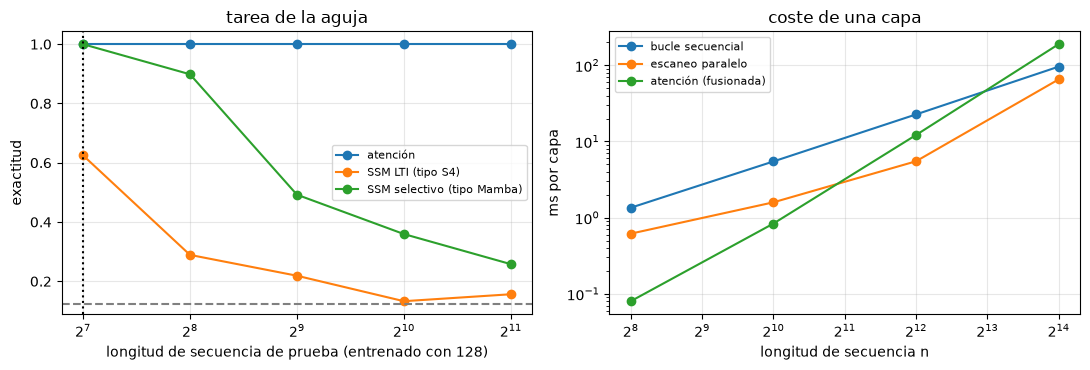

In [12]:
MARK, QUERY, VOCAB = 8, 9, 10                      # los tokens 0..7 son datos, 8 es el marcador, 9 es la consulta

def needle_batch(B, n, g):
    x = torch.randint(0, 8, (B, n), generator=g)
    pos = torch.randint(1, n - 2, (B,), generator=g)
    val = torch.randint(0, 8, (B,), generator=g)
    ar = torch.arange(B)
    x[ar, pos] = MARK; x[ar, pos + 1] = val; x[:, -1] = QUERY
    return x, val

class Front(nn.Module):                            # embedding + convolución causal de ancho 2 (ve el token anterior)
    def __init__(self, d):
        super().__init__(); self.emb = nn.Embedding(VOCAB, d); self.conv = nn.Conv1d(d, d, 2)
    def forward(self, x):
        return F.silu(self.conv(F.pad(self.emb(x).transpose(1, 2), (1, 0)))).transpose(1, 2)

class AttnNet(nn.Module):                          # una capa de atención, leída en la última posición (sin información de posición)
    def __init__(self, d=64):
        super().__init__(); self.f = Front(d); self.q, self.k, self.v = nn.Linear(d, d), nn.Linear(d, d), nn.Linear(d, d); self.out = nn.Linear(d, 8)
    def forward(self, x):
        u = self.f(x)
        att = (self.q(u[:, -1:]) @ self.k(u).transpose(1, 2)) / math.sqrt(u.shape[-1])
        return self.out((att.softmax(-1) @ self.v(u))[:, 0])

class SSMNet(nn.Module):
    # SSM diagonal con estado de tamaño N por canal. selective=True: el paso, B y C dependen de la entrada (tipo Mamba);
    # selective=False: son constantes (tipo S4, un núcleo de convolución fijo)
    def __init__(self, d=64, N=8, selective=True):
        super().__init__(); self.f = Front(d); self.sel = selective
        self.A = nn.Parameter(-torch.rand(d, N) * 0.5 - 0.01)
        if selective:
            self.dt, self.B, self.C = nn.Linear(d, d), nn.Linear(d, N), nn.Linear(d, N)
        else:
            self.dt_c = nn.Parameter(torch.full((d,), -4.0)); self.B_c = nn.Parameter(torch.ones(N)); self.C_c = nn.Parameter(torch.randn(N) / N ** 0.5)
        self.out = nn.Linear(d, 8)
    def forward(self, x):
        u = self.f(x)
        if self.sel:
            dt = F.softplus(self.dt(u) - 3.0); Bt, Ct = self.B(u), self.C(u)
        else:
            dt = F.softplus(self.dt_c)[None, None].expand_as(u); Bt = self.B_c[None, None].expand(*u.shape[:2], -1); Ct = self.C_c[None, None].expand(*u.shape[:2], -1)
        a = torch.exp(dt[..., None] * -F.softplus(self.A))            # (B, n, d, N): decaimiento por token en (0, 1)
        h = scan(a, (dt * u)[..., None] * Bt[:, :, None, :])
        return self.out((h * Ct[:, :, None, :]).sum(-1)[:, -1])

def train_needle(model, n_train=128, steps=300, B=32, seed=0):
    torch.manual_seed(seed); g = torch.Generator().manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), 3e-3)
    for t in range(steps):
        x, y = needle_batch(B, n_train, g)
        loss = F.cross_entropy(model(x), y)
        opt.zero_grad(); loss.backward(); opt.step()
    gt = torch.Generator().manual_seed(999); acc = {}
    with torch.no_grad():
        for n in LENS:
            hits = 0
            for _ in range(2):
                x, y = needle_batch(64, n, gt); hits += (model(x).argmax(-1) == y).sum().item()
            acc[n] = hits / 128
    return acc, loss.item()

LENS = [128, 256, 512, 1024, 2048]
needle = {}
t0 = time.time()
for name, mk in [("atención", lambda: AttnNet()), ("SSM LTI (tipo S4)", lambda: SSMNet(selective=False)), ("SSM selectivo (tipo Mamba)", lambda: SSMNet(selective=True))]:
    t1 = time.time(); acc, last = train_needle(mk()); needle[name] = acc
    print(f"{name:28s} pérdida final de entrenamiento {last:.3f} ({time.time() - t1:.0f} s)  exactitud por longitud de prueba: " + "  ".join(f"{n}: {a:.2f}" for n, a in acc.items()))
print(f"el nivel del azar es 0.125; total {time.time() - t0:.0f} s")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for name, acc in needle.items(): ax[0].plot(LENS, list(acc.values()), "o-", label=name)
ax[0].axvline(128, color="k", ls=":"); ax[0].axhline(0.125, color="gray", ls="--"); ax[0].set_xscale("log", base=2)
ax[0].set_xlabel("longitud de secuencia de prueba (entrenado con 128)"); ax[0].set_ylabel("exactitud"); ax[0].set_title("tarea de la aguja"); ax[0].legend(fontsize=8)
for key, lab in [("seq", "bucle secuencial"), ("scan", "escaneo paralelo"), ("attn", "atención (fusionada)")]: ax[1].plot(NS, tm[key], "o-", label=lab)
ax[1].set_xscale("log", base=2); ax[1].set_yscale("log"); ax[1].set_xlabel("longitud de secuencia n"); ax[1].set_ylabel("ms por capa"); ax[1].set_title("coste de una capa"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Lectura.** El escaneo paralelo reproduce la recurrencia secuencial hasta el error de redondeo. El panel de tiempos muestra la forma de los costes, con la salvedad habitual de la CPU. El bucle de Python crece linealmente (unas 4 veces por cada factor 4 en $n$); nuestro escaneo simple hace trabajo $O(n \log n)$ y es de 2 a 4 veces más rápido que el bucle hasta $n = 4096$, pero crece más que linealmente cuando sus tensores dejan de caber en la caché; el núcleo fusionado de atención es el más rápido con longitudes cortas y crece unas 15 veces por cada factor 4 (cuadrático), y acaba unas 3 veces más lento que el escaneo con $n = 16\,384$. Lo que se traslada a los sistemas reales es el **crecimiento** y, sobre todo, la memoria en el momento de generar: un SSM mantiene un estado de tamaño fijo, la atención una caché que crece con $n$.

La tarea de la aguja es la mitad de calidad. La atención, que puede mirar cualquier posición directamente y no usa información de posición, resuelve la tarea con todas las longitudes de 128 a 2048 (exactitud 1.00; el azar es 0.125). El SSM selectivo también la aprende, con un estado de tamaño fijo, porque su tamaño de paso dependiente de la entrada puede abrirse en el marcador y quedarse cerrado después (exactitud 1.00 con la longitud de entrenamiento), pero **se degrada cuando la secuencia es más larga que aquella con la que entrenó**: 0.90 con 256, 0.49 con 512, 0.36 con 1024 y 0.26 con 2048, porque el decaimiento aprendido con $n = 128$ deja que el valor guardado se desvanezca. El modelo LTI, que no puede elegir qué recordar, aprende la tarea solo en parte con la longitud de entrenamiento (0.62; su pérdida de entrenamiento se queda en 1.66) y cae hacia el azar (0.29 con 256, 0.13 a 0.22 más allá). Así que el juguete respalda tres afirmaciones honestas: (1) la selectividad importa (la idea de Mamba); (2) un estado de tamaño fijo es una memoria con pérdidas cuyo alcance lo fija el entrenamiento, mientras que la atención lo conserva todo a un precio cuadrático; y (3) nuestro SSM es un modelo mínimo de una capa entrenado 300 pasos con una longitud y una semilla; los resultados publicados de Mamba (calidad de modelado de lenguaje cercana a la de transformers del mismo tamaño y un rendimiento de generación 5 veces mayor) vienen de modelos profundos entrenados con miles de millones de tokens y con inicialización ajustada, así que no leas los números de extrapolación de arriba como una propiedad de Mamba en general.

**Modelos reales: Mamba junto a un transformer entrenado con los mismos datos.** `state-spaces/mamba-130m-hf` ([ficha del modelo](https://huggingface.co/state-spaces/mamba-130m-hf); 130 millones de parámetros, entrenado con the Pile; sin licencia en la ficha, código bajo Apache 2.0) y `EleutherAI/pythia-160m` ([ficha del modelo](https://huggingface.co/EleutherAI/pythia-160m); Apache 2.0; 160 millones de parámetros, entrenado también con the Pile y con el mismo tokenizador) son una pareja justa. Medimos la memoria que guardan durante la generación y el tiempo de un paso de decodificación tras prompts de distintas longitudes, además de la pérdida en un pasaje corto. La implementación de Mamba de Hugging Face usada aquí recurre a un bucle de referencia lento (los núcleos fusionados rápidos necesitan una GPU), así que los tiempos de prefill de Mamba no son representativos; el paso de decodificación y el tamaño del estado sí.

In [13]:
def tensor_bytes(obj, seen=None):
    # tamaño total de los tensores que guarda un objeto de caché (sirve para cachés de claves y valores y para estados de Mamba)
    seen = set() if seen is None else seen
    if id(obj) in seen: return 0
    seen.add(id(obj))
    if torch.is_tensor(obj): return obj.numel() * obj.element_size()
    if isinstance(obj, dict): return sum(tensor_bytes(v, seen) for v in obj.values())
    if isinstance(obj, (list, tuple)): return sum(tensor_bytes(v, seen) for v in obj)
    if hasattr(obj, "__dict__"): return sum(tensor_bytes(v, seen) for v in vars(obj).values())
    return 0

PASSAGE = ("The committee reviewed the proposal for the new library and agreed that the building should be open in the evenings. "
           "Several members argued that students need quiet places to study after classes, while others pointed out that the cost of "
           "heating and staff would increase. In the end the committee decided to start with a trial of three months and to publish "
           "the results, so that the decision could be reviewed with real numbers instead of opinions.")
real = {}
try:
    t0 = time.time()
    for name, ctxs in [("EleutherAI/pythia-160m", [64, 512, 1536]), ("state-spaces/mamba-130m-hf", [64, 512])]:
        tok = AutoTokenizer.from_pretrained(name)
        mdl = AutoModelForCausalLM.from_pretrained(name, torch_dtype=torch.float32).eval()
        short = name.split("/")[1]
        pid = tok(PASSAGE, return_tensors="pt")
        with torch.no_grad():
            loss = mdl(**pid, labels=pid["input_ids"]).loss.item()
        gen = mdl.generate(**tok("The history of computing began with", return_tensors="pt"), max_new_tokens=24, do_sample=False, pad_token_id=tok.eos_token_id)
        print(f"{short}: {sum(p.numel() for p in mdl.parameters())/1e6:.0f} M parámetros, pérdida en el pasaje {loss:.2f} nats/token ({pid['input_ids'].shape[1]} tokens)")
        print("   muestra:", repr(tok.decode(gen[0])[:150]))
        for ctx in ctxs:
            ids = torch.randint(100, 5000, (1, ctx))
            with torch.no_grad():
                out = mdl(ids, use_cache=True)
                cache = getattr(out, "past_key_values", None) or getattr(out, "cache_params", None)
                nbytes = tensor_bytes(cache); nxt = ids[:, -1:]; ts = []
                for i in range(8):
                    t = time.perf_counter()
                    if "mamba" in name:
                        out = mdl(input_ids=nxt, cache_params=cache, use_cache=True, cache_position=torch.tensor([ctx + i])); cache = out.cache_params
                    else:
                        out = mdl(nxt, past_key_values=cache, use_cache=True); cache = out.past_key_values
                    ts.append(time.perf_counter() - t)
            real[(short, ctx)] = (nbytes / 1e6, 1000 * statistics.median(ts[2:]))
            print(f"   prompt {ctx:5d} tokens: caché/estado {nbytes/1e6:7.2f} MB   paso de decodificación {1000 * statistics.median(ts[2:]):6.1f} ms")
        del mdl
    print(f"{time.time() - t0:.0f} s")
except Exception as e:
    print("Comparación con modelos reales omitida (sin red o versión de transformers incompatible):", repr(e)[:200])

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 148/148 [00:00<00:00, 6127.42it/s]

pythia-160m: 162 M parámetros, pérdida en el pasaje 3.40 nats/token (82 tokens)
   muestra: 'The history of computing began with the invention of the computer in the early 1900s. The first computer was a computer that was developed by the Amer'


   prompt    64 tokens: caché/estado    4.72 MB   paso de decodificación   37.8 ms


   prompt   512 tokens: caché/estado   37.75 MB   paso de decodificación   39.3 ms


   prompt  1536 tokens: caché/estado  113.25 MB   paso de decodificación   43.1 ms


Loading weights:   0%|          | 0/242 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 242/242 [00:00<00:00, 10202.35it/s]

mamba-130m-hf: 129 M parámetros, pérdida en el pasaje 3.22 nats/token (82 tokens)
   muestra: 'The history of computing began with the invention of the computer in the early 1900s. The first computer was a personal computer, which was a computer'


   prompt    64 tokens: caché/estado    2.95 MB   paso de decodificación   38.5 ms


   prompt   512 tokens: caché/estado    2.95 MB   paso de decodificación   38.1 ms
10 s


**Lectura.** El estado de Mamba es **constante**: unos 3 MB tanto si el prompt tiene 64 como 512 tokens (y seguiría en 3 MB con 100 000), mientras que la caché del transformer crece en proporción al prompt, de 4.7 MB con 64 tokens a 113 MB con 1536 tokens, y llegaría a gigabytes con las longitudes de la sección 1. El tiempo del paso de decodificación, en cambio, es casi igual en ambos aquí (unos 37 a 42 ms; el del transformer sube despacio con la longitud del prompt y el paso de Mamba se queda en unos 38 ms): con 130 a 160 millones de parámetros en una CPU, un paso está dominado por la lectura de los pesos y por la sobrecarga de Python, y la caché es una parte pequeña del tráfico, así que la ventaja del estado fijo se nota primero en memoria y en velocidad solo con contextos largos y lotes grandes. Ambos modelos continúan el prompt con texto fluido pero corriente, y las pérdidas en el pasaje corto son cercanas (3.40 para Pythia, 3.22 para Mamba, con 82 tokens: un pasaje corto no puede ordenarlos). Los benchmarks publicados sitúan a Mamba a la calidad de un transformer de su tamaño en modelado de lenguaje, mientras se queda atrás en tareas que exigen recuerdo exacto del contexto, que es el compromiso de memoria con pérdidas visto en la tarea de la aguja. Por eso muchos modelos recientes mezclan los dos: unas pocas capas de atención dentro de una pila de capas SSM (híbridos como Jamba, Lieber et al., 2024).

## 7. Entrenar a gran escala

Un modelo de 7000 millones de parámetros necesita unos 110 GB de estado de entrenamiento (sección 1) y billones de tokens; ningún dispositivo por sí solo guarda lo primero ni termina lo segundo en un tiempo razonable. Entrenar a gran escala es una pila de técnicas que intercambian aritmética, memoria y comunicación entre sí. Las vemos en el orden en que las encuentra un profesional.

### 7.1 Precisión mixta

Los números se guardan en un **formato**: fp32 (32 bits: 1 de signo, 8 de exponente, 23 de mantisa), fp16 (16 bits: 5 de exponente, 10 de mantisa) o **bfloat16** (bf16: 16 bits, 8 de exponente como fp32, solo 7 de mantisa). El exponente fija el **rango** y la mantisa la **precisión**. El entrenamiento en **precisión mixta** (Micikevicius et al., 2017) ejecuta los productos de matrices en un formato de 16 bits, lo que reduce a la mitad el tráfico de memoria y, en hardware con unidades de 16 bits, multiplica el rendimiento, mientras se conserva una **copia maestra** de 32 bits de los pesos y del estado del optimizador, porque las pequeñas actualizaciones del final del entrenamiento se perderían por redondeo en 16 bits.

Con **fp16** aparece un segundo problema: sus números positivos más pequeños son mucho mayores que los de fp32, de modo que los gradientes pequeños se **desbordan por abajo** (underflow) hasta cero. El remedio es el **escalado de la pérdida**: se multiplica la pérdida por una constante grande $s$ antes del paso hacia atrás, de modo que todos los gradientes son $s$ veces mayores y sobreviven, y se divide por $s$ antes de actualizar los pesos. El escalado *dinámico* de la pérdida sube $s$ cuando pasan muchos pasos sin problema y lo divide por dos (saltando el paso) cuando aparece un infinito. **bf16** tiene el rango de fp32, así que no necesita escalado de la pérdida, a cambio de una precisión más gruesa; por eso se ha convertido en la opción por defecto en el hardware reciente. Miramos los números con gradientes reales.

In [14]:
import contextlib
print(f"{'formato':9s} {'mayor':>12s} {'menor normal':>16s} {'épsilon (precisión)':>20s}")
for dt in [torch.float32, torch.bfloat16, torch.float16]:
    fi = torch.finfo(dt); print(f"{str(dt).split('.')[1]:9s} {fi.max:12.3e} {fi.tiny:16.3e} {fi.eps:20.3e}")
print("fp16(1e-8) =", torch.tensor(1e-8).to(torch.float16).item(), "   fp16(70000) =", torch.tensor(70000.0).to(torch.float16).item(),
      "   bf16(1.001) =", torch.tensor(1.001).to(torch.bfloat16).item(), "   bf16(1e-8) =", f"{torch.tensor(1e-8).to(torch.bfloat16).item():.3e}")

# gradientes reales de un modelo de lenguaje pequeño: ¿qué les pasa en 16 bits, con y sin escalado de la pérdida?
torch.manual_seed(0); g = torch.Generator().manual_seed(0)
m_ = TinyLM(V=128, d=128, L=3, H=8, n_max=96)
xb, yb = get_batch(train_data, 32, 96, g)
F.cross_entropy(m_(xb).reshape(-1, 128), yb.reshape(-1)).backward()
grad = torch.cat([p.grad.flatten() for p in m_.parameters()])
nz = grad != 0
print(f"\n{nz.sum().item():,} entradas de gradiente no nulas; magnitud mediana {grad[nz].abs().median().item():.1e}, la menor {grad[nz].abs().min().item():.1e}")
print(f"entradas por debajo del menor número normal de fp16 (6.1e-05), que pierden precisión o desaparecen en fp16: {(grad[nz].abs() < 6.1e-5).float().mean().item():.1%}")
print(f"{'convertido a':>16s} {'escala pérdida':>11s} {'pasó a cero':>12s} {'bajo 6.1e-05 (subnormal)':>26s} {'pasó a inf':>11s}")
for dt, s in [(torch.float16, 1), (torch.float16, 2 ** 8), (torch.float16, 2 ** 16), (torch.float16, 2 ** 24), (torch.bfloat16, 1)]:
    c16 = (grad * s).to(dt)
    sub = f"{((c16[nz].abs() < 6.1e-5) & (c16[nz] != 0)).float().mean().item():.1%}" if dt == torch.float16 else "n/a"
    print(f"{str(dt).split('.')[1]:>16s} {s:>11d} {(c16[nz] == 0).float().mean().item():12.3%} {sub:>26s} {torch.isinf(c16).float().mean().item():11.3%}")

formato          mayor     menor normal  épsilon (precisión)
float32      3.403e+38        1.175e-38            1.192e-07
bfloat16     3.390e+38        1.175e-38            7.812e-03
float16      6.550e+04        6.104e-05            9.766e-04
fp16(1e-8) = 0.0    fp16(70000) = inf    bf16(1.001) = 1.0    bf16(1e-8) = 1.001e-08

630,528 entradas de gradiente no nulas; magnitud mediana 3.8e-04, la menor 3.3e-10
entradas por debajo del menor número normal de fp16 (6.1e-05), que pierden precisión o desaparecen en fp16: 15.9%
    convertido a escala pérdida  pasó a cero   bajo 6.1e-05 (subnormal)  pasó a inf
         float16           1       0.008%                      15.8%      0.000%
         float16         256       0.000%                       0.1%      0.000%
         float16       65536       0.000%                       0.0%      0.000%
         float16    16777216       0.000%                       0.0%      4.251%
        bfloat16           1       0.000%                        

In [15]:
# velocidad y pérdida de un paso de entrenamiento en fp32 y con autocast de bfloat16 en esta CPU
def train_steps(amp, steps=12, seed=0):
    torch.manual_seed(seed); gg = torch.Generator().manual_seed(seed)
    m = TinyLM(V=128, d=256, L=4, H=8, n_max=128)
    opt = torch.optim.AdamW(m.parameters(), lr=2e-3)
    ts, losses = [], []
    for t in range(steps):
        xb, yb = get_batch(train_data, 16, 128, gg)
        t0_ = time.perf_counter()
        with (torch.autocast("cpu", dtype=torch.bfloat16) if amp else contextlib.nullcontext()):
            logits = m(xb)
        loss = F.cross_entropy(logits.float().reshape(-1, 128), yb.reshape(-1))
        opt.zero_grad(); loss.backward(); opt.step()
        ts.append(time.perf_counter() - t0_); losses.append(loss.item())
    return statistics.median(ts[2:]), losses

cpu_flags = open("/proc/cpuinfo").read() if os.path.exists("/proc/cpuinfo") else ""
print("La CPU tiene instrucciones bf16 nativas (avx512_bf16 o AMX):", ("avx512_bf16" in cpu_flags) or ("amx_bf16" in cpu_flags))
res_amp = {}
for amp in [False, True]:
    t_med, losses = train_steps(amp); res_amp[amp] = (t_med, losses)
    print(f"{'bf16 autocast' if amp else 'fp32':14s} paso mediano {1000 * t_med:7.0f} ms   pérdida tras 12 pasos {losses[-1]:.3f}")
print(f"razón de velocidad fp32 / bf16: {res_amp[False][0] / res_amp[True][0]:.2f}")

La CPU tiene instrucciones bf16 nativas (avx512_bf16 o AMX): True


fp32           paso mediano     214 ms   pérdida tras 12 pasos 2.940


bf16 autocast  paso mediano     104 ms   pérdida tras 12 pasos 2.940
razón de velocidad fp32 / bf16: 2.06


**Lectura.** La tabla de formatos muestra por qué los dos formatos de 16 bits se comportan distinto: fp16 tiene un épsilon 8 veces más fino que bf16 pero un menor número normal de $6 \times 10^{-5}$ y un máximo de 65 504, de modo que 1e-8 pasa a ser 0 y 70 000 pasa a ser infinito, mientras que bf16 mantiene el rango de fp32 y pierde precisión en su lugar (1.001 se redondea a 1.0). En los gradientes reales de nuestro modelo pequeño, el 15.9 % de las entradas no nulas son menores que el menor número normal de fp16: en fp16 simple el 0.008 % de ellas se redondea a cero exacto y el 15.8 % cae en el rango subnormal, donde se va perdiendo precisión; una escala de pérdida de $2^{8}$ baja la parte subnormal al 0.1 % y $2^{16}$ casi a nada, mientras que $2^{24}$ es demasiado y convierte el 4.3 % de las entradas en infinito, que es exactamente lo que el escalado dinámico detecta y de lo que se retira. En un modelo pequeño solo se ve afectada una minoría; en modelos más profundos y grandes los gradientes son menores y la pérdida sin escalado es seria. bf16 no pierde nada por desbordamiento por abajo sin ninguna escala. Las líneas de tiempos son la parte honesta de la historia de la CPU: el beneficio de la aritmética de 16 bits depende por completo del soporte del hardware. Esta CPU tiene instrucciones nativas de bf16 y el paso con autocast es unas 2 veces más rápido; en una CPU sin ellas es más lento que fp32, porque los valores se convierten de ida y vuelta. La pérdida tras 12 pasos es idéntica hasta el tercer decimal, que es la propiedad que importa: la precisión mixta debe cambiar la velocidad y la memoria, no el resultado del entrenamiento.

### 7.2 Acumulación de gradientes y checkpointing de gradientes

Dos maneras de meter un lote grande o un modelo profundo en memoria limitada, cada una pagando con tiempo.

**Acumulación de gradientes.** Para entrenar con un lote de $B$ secuencias cuando solo caben $B/m$ en memoria, se ejecutan $m$ microlotes, se suman sus gradientes (cada pérdida dividida por $m$) y se da **un** solo paso del optimizador. El resultado es matemáticamente el mismo gradiente, y las activaciones guardadas son las de un solo microlote; el coste es que los microlotes se ejecutan uno tras otro.

**Checkpointing de gradientes** (también llamado recomputación de activaciones; Chen et al., 2016). El paso hacia atrás necesita las activaciones del paso hacia delante. En lugar de guardarlas todas, se guarda solo la entrada de cada bloque (o de cada pocos bloques) y se **recalcula** el resto del paso hacia delante del bloque durante el paso hacia atrás. La memoria de activaciones baja de $O(L)$ bloques a más o menos un bloque más $L$ entradas pequeñas, al precio de un paso hacia delante extra (un 30 % más de aritmética aproximadamente). Primero contamos los bytes que guarda PyTorch para el paso hacia atrás, y después medimos la memoria pico y el tiempo de pasos de entrenamiento reales en procesos separados.

In [16]:
def saved_bytes(model, x, y, micro=1):
    # tamaño total de los tensores de activación guardados para el paso hacia atrás (los parámetros no se cuentan)
    pptr = {p.untyped_storage().data_ptr() for p in model.parameters()}
    store = {}
    def pack(t):
        s = t.untyped_storage()
        if s.data_ptr() not in pptr: store[s.data_ptr()] = s.nbytes()
        return t
    with torch.autograd.graph.saved_tensors_hooks(pack, lambda t: t):
        loss = F.cross_entropy(model(x).reshape(-1, 128), y.reshape(-1))
    loss.backward()
    return sum(store.values())

torch.manual_seed(0)
base = TinyLM(V=128, d=128, L=3, H=8, n_max=96)
xb, yb = get_batch(train_data, 32, 96, torch.Generator().manual_seed(1))

# acumulación de gradientes: mismo gradiente, activaciones de un solo microlote
def grad_with_micro(micro):
    base.zero_grad()
    for xc, yc in zip(xb.chunk(micro), yb.chunk(micro)):
        (F.cross_entropy(base(xc).reshape(-1, 128), yc.reshape(-1)) / micro).backward()
    return torch.cat([p.grad.flatten() for p in base.parameters()])
g1 = grad_with_micro(1)
print("acumulación de gradientes (lote de 32 secuencias):")
for micro in [2, 4, 8]:
    gm = grad_with_micro(micro)
    sv = saved_bytes(base, xb[: 32 // micro], yb[: 32 // micro])
    print(f"  {micro} microlotes de {32 // micro:2d}: |diferencia de gradiente| máx. = {(gm - g1).abs().max().item():.1e}   activaciones guardadas a la vez: {sv / 1e6:6.1f} MB")
print(f"  1 lote de 32:              activaciones guardadas a la vez: {saved_bytes(base, xb, yb) / 1e6:6.1f} MB")

# checkpointing de gradientes: activaciones guardadas, con y sin él
m_plain = TinyLM(V=128, d=128, L=6, H=8, n_max=96); m_ck = TinyLM(V=128, d=128, L=6, H=8, n_max=96, ckpt=True)
m_ck.load_state_dict(m_plain.state_dict())
print(f"\ncheckpointing de gradientes, modelo de 6 capas, lote 32 x 96 tokens: guardado sin él {saved_bytes(m_plain, xb, yb) / 1e6:.1f} MB, con él {saved_bytes(m_ck, xb, yb) / 1e6:.1f} MB")
gp = torch.cat([p.grad.flatten() for p in m_plain.parameters()]); gc = torch.cat([p.grad.flatten() for p in m_ck.parameters()])
print(f"gradientes idénticos: |diferencia| máx. = {(gp - gc).abs().max().item():.1e}")

CKPT = '''
import sys, json, statistics, torch, torch.nn.functional as F
sys.path.insert(0, sys.argv[1]); torch.set_num_threads(int(sys.argv[3])); torch.manual_seed(0)
from tinylm import TinyLM
from memtools import measure_peak
m = TinyLM(V=256, d=256, L=8, H=4, n_max=256, ckpt=bool(int(sys.argv[2])))
opt = torch.optim.Adam(m.parameters(), lr=1e-3)
def step(B):
    x = torch.randint(0, 256, (B, 257)); loss = F.cross_entropy(m(x[:, :-1]).reshape(-1, 256), x[:, 1:].reshape(-1))
    opt.zero_grad(); loss.backward(); opt.step()
step(1)                                                           # se reserva el estado del optimizador antes de tomar la referencia
runs = [measure_peak(lambda: step(16)) for _ in range(4)]
print(json.dumps(dict(extra_mb=runs[0][1], s=statistics.median(r[0] for r in runs[1:]))))
'''
print("\nmedido en procesos separados (8 capas, ancho 256, lote 16 x 256 tokens):")
ck = {}
for flag in [0, 1]:
    ck[flag] = json.loads(run_script("ckpt_probe.py", CKPT, flag, NT))
    print(f"  checkpointing {'sí' if flag else 'no'}: memoria pico extra {ck[flag]['extra_mb']:7.0f} MB   tiempo por paso {ck[flag]['s']:.2f} s")
print(f"  memoria {ck[0]['extra_mb'] / max(ck[1]['extra_mb'], 1):.1f}x menor, tiempo {ck[1]['s'] / ck[0]['s']:.2f}x")

acumulación de gradientes (lote de 32 secuencias):


  2 microlotes de 16: |diferencia de gradiente| máx. = 6.0e-08   activaciones guardadas a la vez:   54.4 MB


  4 microlotes de  8: |diferencia de gradiente| máx. = 6.0e-08   activaciones guardadas a la vez:   27.2 MB


  8 microlotes de  4: |diferencia de gradiente| máx. = 6.0e-08   activaciones guardadas a la vez:   13.6 MB


  1 lote de 32:              activaciones guardadas a la vez:  108.8 MB



checkpointing de gradientes, modelo de 6 capas, lote 32 x 96 tokens: guardado sin él 212.8 MB, con él 14.2 MB
gradientes idénticos: |diferencia| máx. = 0.0e+00

medido en procesos separados (8 capas, ancho 256, lote 16 x 256 tokens):


  checkpointing no: memoria pico extra     850 MB   tiempo por paso 0.85 s


  checkpointing sí: memoria pico extra     179 MB   tiempo por paso 1.49 s
  memoria 4.7x menor, tiempo 1.75x


**Lectura.** La acumulación de gradientes da el mismo gradiente que el lote completo hasta el error de redondeo (diferencias de $6 \times 10^{-8}$), y las activaciones guardadas en cada momento bajan en proporción al tamaño del microlote (109 MB para 32 secuencias, 54, 27 y 14 MB para microlotes de 16, 8 y 4), que es todo el punto: el tamaño del lote es una decisión estadística, el microlote es una decisión de memoria. El checkpointing deja los gradientes idénticos y reduce 15 veces los bytes guardados para el paso hacia atrás (de 213 MB a 14 MB); la medición a nivel de proceso coincide en la dirección pero de forma menos espectacular (memoria pico de 850 MB sin y 204 MB con checkpointing, unas 4 veces menos, porque incluye búferes temporales, el bloque recalculado y el asignador de memoria) a un coste en tiempo por paso de 1.3 a 1.7 veces según la ejecución en esta máquina compartida, ya que se repite el paso hacia delante. Las grandes ejecuciones de entrenamiento usan ambos, además de recomputar solo las partes más baratas de guardar de cada bloque (recomputación "selectiva").

### 7.3 Paralelismo de datos, de verdad

El **paralelismo de datos** mantiene una copia completa del modelo en cada uno de $W$ trabajadores. Cada trabajador toma una porción distinta del lote, calcula su gradiente, y los trabajadores **promedian los gradientes con un all-reduce** (cada trabajador termina con la suma de todos) antes de que cada uno dé el mismo paso del optimizador, de modo que las copias siguen idénticas. Con un lote global fijo, la aritmética por trabajador baja en un factor $W$ mientras que la comunicación por paso se queda del tamaño del gradiente: un all-reduce en **anillo** envía $2\,\frac{W-1}{W}$ veces el tamaño del gradiente por trabajador, casi independiente de $W$. Que el paralelismo de datos escale depende entonces de cómo se compara el tiempo de paso con el tiempo del all-reduce. El `DistributedDataParallel` de PyTorch solapa el all-reduce de las capas anteriores con el cálculo hacia atrás de las posteriores.

A continuación lo ejecutamos de verdad: 1, 2 y 4 procesos separados en esta máquina, un hilo cada uno, conectados con la biblioteca de comunicación `gloo` de `torch.distributed` (el equivalente en CPU de NCCL en las GPU), entrenando un transformer de 3.3 millones de parámetros con tokens aleatorios (la velocidad no depende de los datos). Medimos el paso completo, y el all-reduce de un búfer del tamaño del gradiente por separado. Dos configuraciones: un lote global de 32 secuencias, donde hay mucha aritmética por paso, y un lote global de 4, donde hay poca y la comunicación se nota. Una última ejecución usa ZeRO-1 (repartir el estado del optimizador, sección 7.4) en 4 procesos para contar los bytes del optimizador que guarda cada trabajador.

modelo: 3,323,136 parámetros (13.3 MB de gradientes en fp32); 37 s
 lote global  trabaj.  paso (ms) aceleración  eficiencia  all-reduce (ms) comun. / paso  enviado/trabaj. (MB)
          32        1        481     1.00x        100%              0.0           0%                   0.0
          32        2        260     1.85x         93%              7.4           3%                  13.3
          32        4        151     3.19x         80%             12.5           8%                  19.9
           4        1         71     1.00x        100%              0.0           0%                   0.0
           4        2         48     1.47x         74%              3.7           8%                  13.3
           4        4         45     1.60x         40%             15.7          35%                  19.9

bytes de estado de Adam por trabajador, 4 trabajadores: simple 26.6 MB, ZeRO-1 6.8 MB


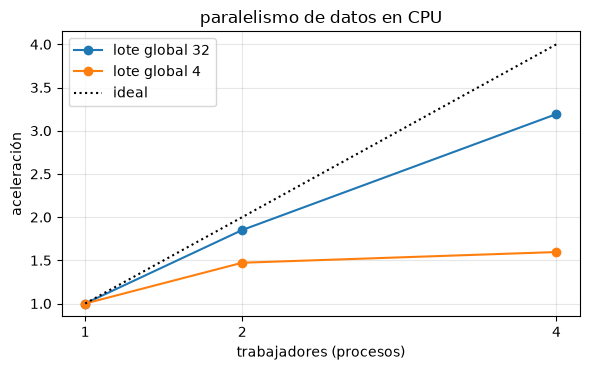

In [17]:
DDP_SRC = '''
import os, sys, json, time, statistics
os.environ["OMP_NUM_THREADS"] = "1"; os.environ["MKL_NUM_THREADS"] = "1"
import torch, torch.nn as nn, torch.nn.functional as F
import torch.distributed as dist, torch.multiprocessing as mp
from torch.nn.parallel import DistributedDataParallel as DDP

class Net(nn.Module):
    def __init__(self, V=256, d=256, L=4, H=4):
        super().__init__(); self.emb = nn.Embedding(V, d); self.pos = nn.Parameter(torch.zeros(128, d))
        layer = nn.TransformerEncoderLayer(d, H, 4 * d, dropout=0.0, batch_first=True, norm_first=True)
        self.enc = nn.TransformerEncoder(layer, L, enable_nested_tensor=False); self.head = nn.Linear(d, V)
    def forward(self, x):
        mask = torch.triu(torch.ones(x.shape[1], x.shape[1], dtype=torch.bool), 1)
        return self.head(self.enc(self.emb(x) + self.pos[: x.shape[1]], mask=mask))

def worker(rank, world, gbatch, steps, zero, port, q):
    torch.set_num_threads(1)
    os.environ.update(MASTER_ADDR="127.0.0.1", MASTER_PORT=str(port))
    dist.init_process_group("gloo", rank=rank, world_size=world)
    torch.manual_seed(0); model = Net(); nparams = sum(p.numel() for p in model.parameters())
    ddp = DDP(model)
    if zero:
        from torch.distributed.optim import ZeroRedundancyOptimizer
        opt = ZeroRedundancyOptimizer(ddp.parameters(), optimizer_class=torch.optim.Adam, lr=1e-3)
    else:
        opt = torch.optim.Adam(ddp.parameters(), lr=1e-3)
    local = gbatch // world
    g = torch.Generator().manual_seed(1234 + rank)
    times = []
    for t in range(steps):
        x = torch.randint(0, 256, (local, 65), generator=g)
        t0 = time.perf_counter()
        loss = F.cross_entropy(ddp(x[:, :-1]).reshape(-1, 256), x[:, 1:].reshape(-1))
        opt.zero_grad(); loss.backward(); opt.step()
        times.append(time.perf_counter() - t0)
    buf = torch.zeros(nparams); comm = []
    for t in range(8):
        dist.barrier(); t0 = time.perf_counter(); dist.all_reduce(buf); comm.append(time.perf_counter() - t0)
    inner = opt.optim if zero else opt
    state = sum(v.numel() * v.element_size() for st in inner.state.values() for v in st.values() if torch.is_tensor(v) and v.dim() > 0)
    if rank == 0:
        q.put(dict(world=world, step=statistics.median(times[2:]), comm=statistics.median(comm[2:]), params=nparams, state_bytes=state))
    dist.destroy_process_group()

if __name__ == "__main__":
    world, gbatch, steps, zero, port = (int(a) for a in sys.argv[2:7])
    q = mp.get_context("spawn").Queue()
    mp.spawn(worker, args=(world, gbatch, steps, zero, port, q), nprocs=world, join=True)
    print(json.dumps(q.get()))
'''
import socket
def free_port():
    with socket.socket() as s:
        s.bind(("127.0.0.1", 0)); return s.getsockname()[1]

ddp_res = {}
t0 = time.time()
try:
    worlds = [w for w in (1, 2, 4) if w <= (os.cpu_count() or 1)]
    for gb in (32, 4):
        for w in worlds:
            ddp_res[(gb, w)] = json.loads(run_script("ddp_bench.py", DDP_SRC, w, gb, 8, 0, free_port()))
    zr = json.loads(run_script("ddp_bench.py", DDP_SRC, worlds[-1], 32, 4, 1, free_port())) if worlds[-1] > 1 else None
    npar_ddp = ddp_res[(32, 1)]["params"]
    print(f"modelo: {npar_ddp:,} parámetros ({4 * npar_ddp / 1e6:.1f} MB de gradientes en fp32); {time.time() - t0:.0f} s")
    print(f"{'lote global':>12s} {'trabaj.':>8s} {'paso (ms)':>10s} {'aceleración':>9s} {'eficiencia':>11s} {'all-reduce (ms)':>16s} {'comun. / paso':>12s} {'enviado/trabaj. (MB)':>21s}")
    for (gb, w), r in ddp_res.items():
        t1_ = ddp_res[(gb, 1)]["step"]
        print(f"{gb:12d} {w:8d} {1000 * r['step']:10.0f} {t1_ / r['step']:8.2f}x {t1_ / r['step'] / w:11.0%} {1000 * r['comm']:16.1f} {r['comm'] / r['step']:12.0%} {2 * (w - 1) / w * 4 * npar_ddp / 1e6:21.1f}")
    if zr:
        print(f"\nbytes de estado de Adam por trabajador, {worlds[-1]} trabajadores: simple {ddp_res[(32, worlds[-1])]['state_bytes'] / 1e6:.1f} MB, ZeRO-1 {zr['state_bytes'] / 1e6:.1f} MB")
    fig, ax = plt.subplots(figsize=(6, 3.8))
    for gb in (32, 4):
        ax.plot(worlds, [ddp_res[(gb, 1)]["step"] / ddp_res[(gb, w)]["step"] for w in worlds], "o-", label=f"lote global {gb}")
    ax.plot(worlds, worlds, "k:", label="ideal"); ax.set_xlabel("trabajadores (procesos)"); ax.set_ylabel("aceleración"); ax.set_xticks(worlds); ax.legend(); ax.set_title("paralelismo de datos en CPU")
    plt.tight_layout(); plt.show()
except Exception as e:
    print("Falló la ejecución distribuida:", repr(e)[:300])

**Lectura.** Con 32 secuencias por paso el trabajo se reparte bien: dos trabajadores dan una aceleración de aproximadamente 1.8 y cuatro trabajadores de aproximadamente 3.4, una eficiencia del 85 al 90 %, porque cada paso hace decenas de gigaflops mientras que el all-reduce de 13 MB tarda de unos pocos a una docena de milisegundos (el 3 % y el 8 % del paso). Con un lote global de 4 la aritmética por trabajador es mínima, el mismo all-reduce pasa a ser el 15 % y luego el 37 % del paso y la aceleración se aplana (unas 1.3 con dos trabajadores y 1.6 con cuatro, eficiencias del 65 % y 40 %): **la comunicación no se reduce al añadir trabajadores, así que los pasos pequeños dejan de escalar primero**. Por eso el entrenamiento a gran escala aumenta el tamaño del lote con el número de trabajadores (hasta el punto en que un lote mayor ya no ayuda a la optimización), solapa comunicación con cálculo, y corre en interconexiones rápidas (cientos de gigabytes por segundo entre GPU de un nodo, frente a los pocos gigabytes por segundo de este enlace local). Los números vienen de una máquina de nube compartida en la que los "núcleos" son hilos de hardware que comparten unidades de ejecución, así que espera que varíen unos pocos puntos porcentuales entre ejecuciones. La última línea muestra ZeRO-1 funcionando: cada uno de los cuatro trabajadores guarda una cuarta parte del estado de Adam (6.8 MB en lugar de 26.6 MB).

### 7.4 Cuando una copia del modelo no cabe: reparto en paralelismo de tensores, de tubería y ZeRO/FSDP

El paralelismo de datos necesita el modelo completo, los gradientes y el estado del optimizador en cada trabajador. Pasados unos pocos miles de millones de parámetros eso falla (sección 1), y el modelo tiene que **partirse** entre dispositivos. Hay tres maneras, y las grandes ejecuciones las combinan ("paralelismo 3D").

```
 Paralelo de datos (DP)     Paralelo de tensores (TP)     Paralelo de tubería (PP)
 cada dispositivo: todas    cada dispositivo: una parte   cada dispositivo: algunas capas
 las capas, datos distintos de cada capa, mismos datos   los microlotes fluyen por ellas

  dev0 [L1 L2 L3 L4]         dev0 [L1a L2a L3a L4a]        dev0 [L1 L2]  --->
  dev1 [L1 L2 L3 L4]         dev1 [L1b L2b L3b L4b]        dev1 [L3 L4]  --->
  all-reduce del gradiente   all-reduce dentro de cada     se envían activaciones entre
                             capa                          etapas
```

* El **paralelismo de tensores** (Megatron-LM; Shoeybi et al., 2019) parte cada matriz de pesos. En el bloque feed-forward $y = W_2\,\sigma(W_1 x)$ se parte $W_1$ **por columnas** y $W_2$ **por filas**: cada dispositivo calcula su parte de la capa oculta, aplica $\sigma$ localmente y produce una salida parcial, y un all-reduce (una suma) por bloque completa $y$. Necesita enlaces muy rápidos, así que se usa dentro de un nodo.
* El **paralelismo de tubería** (GPipe, Huang et al., 2018; PipeDream) da grupos consecutivos de capas a dispositivos distintos y corta el lote en $m$ **microlotes** que fluyen por las etapas. El precio es la **burbuja**: los dispositivos están ociosos mientras la tubería se llena y se vacía, una fracción $\frac{p - 1}{m + p - 1}$ del tiempo para $p$ etapas, por lo que $m$ debe ser mucho mayor que $p$.
* **ZeRO** (zero redundancy optimiser, optimizador sin redundancia; Rajbhandari et al., 2019) y su implementación en PyTorch **FSDP** (fully sharded data parallel, paralelo de datos totalmente repartido; Zhao et al., 2023) mantienen el paralelismo de datos pero eliminan la redundancia: con $W$ trabajadores, la **etapa 1** reparte el estado del optimizador, la **etapa 2** también los gradientes y la **etapa 3** (lo que hace FSDP) también los parámetros, reuniendo los pesos de cada capa justo a tiempo para su paso hacia delante y hacia atrás y liberándolos después. Con $\Psi$ parámetros y los 16 bytes por parámetro de la sección 1, la memoria por trabajador es $16\Psi$ (simple), $4\Psi + 12\Psi/W$, $2\Psi + 14\Psi/W$ y $16\Psi/W$ para las etapas 0 a 3. El coste es más comunicación (la etapa 3 mueve unas 1.5 veces los datos del paralelismo de datos simple).

Comprobamos numéricamente el reparto en paralelismo de tensores y calculamos la memoria de ZeRO y la burbuja de la tubería.

MLP con paralelismo de tensores (2 dispositivos) frente a un dispositivo: |diferencia| máx. = 2.0e-13  (un all-reduce = la suma)
  7.5 miles de millones de parámetros,  64 trabajadores (GB por trabajador, solo estado del modelo): plain DP   120.0, ZeRO-1    31.4, ZeRO-2    16.6, ZeRO-3 / FSDP     1.9
 70.0 miles de millones de parámetros,  64 trabajadores (GB por trabajador, solo estado del modelo): plain DP  1120.0, ZeRO-1   293.1, ZeRO-2   155.3, ZeRO-3 / FSDP    17.5
 70.0 miles de millones de parámetros, 512 trabajadores (GB por trabajador, solo estado del modelo): plain DP  1120.0, ZeRO-1   281.6, ZeRO-2   141.9, ZeRO-3 / FSDP     2.2


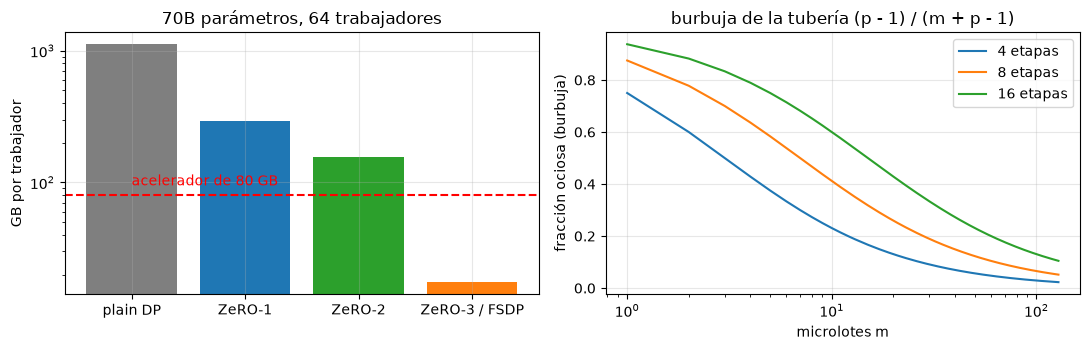

In [18]:
# paralelismo de tensores: se parte W1 por columnas y W2 por filas entre 2 "dispositivos"; las salidas parciales suman el resultado exacto
torch.manual_seed(0)
x = torch.randn(5, 64, dtype=torch.float64); W1 = torch.randn(64, 256, dtype=torch.float64); W2 = torch.randn(256, 64, dtype=torch.float64)
full = F.gelu(x @ W1) @ W2
parts = [F.gelu(x @ W1[:, i::2]) @ W2[i::2] for i in (0, 1)]          # el dispositivo i guarda la mitad de las columnas de W1 y las filas correspondientes de W2
print(f"MLP con paralelismo de tensores (2 dispositivos) frente a un dispositivo: |diferencia| máx. = {(parts[0] + parts[1] - full).abs().max().item():.1e}  (un all-reduce = la suma)")

# ZeRO: memoria por trabajador para un modelo de 7.5B en 64 trabajadores (el ejemplo del artículo de ZeRO) y para uno de 70B
def zero_mem(psi, W):
    return {"plain DP": 16 * psi, "ZeRO-1": 4 * psi + 12 * psi / W, "ZeRO-2": 2 * psi + 14 * psi / W, "ZeRO-3 / FSDP": 16 * psi / W}
for psi, W in [(7.5e9, 64), (70e9, 64), (70e9, 512)]:
    z = zero_mem(psi, W)
    print(f"{psi/1e9:5.1f} miles de millones de parámetros, {W:3d} trabajadores (GB por trabajador, solo estado del modelo): " + ", ".join(f"{k} {v/1e9:7.1f}" for k, v in z.items()))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
z = zero_mem(70e9, 64); ax[0].bar(list(z), [v / 1e9 for v in z.values()], color=["tab:gray", "tab:blue", "tab:green", "tab:orange"])
ax[0].axhline(80, color="r", ls="--"); ax[0].text(0, 95, "acelerador de 80 GB", color="r"); ax[0].set_yscale("log"); ax[0].set_ylabel("GB por trabajador"); ax[0].set_title("70B parámetros, 64 trabajadores")
for p in (4, 8, 16):
    ms = np.arange(1, 129); ax[1].plot(ms, (p - 1) / (ms + p - 1), label=f"{p} etapas")
ax[1].set_xscale("log"); ax[1].set_xlabel("microlotes m"); ax[1].set_ylabel("fracción ociosa (burbuja)"); ax[1].set_title("burbuja de la tubería (p - 1) / (m + p - 1)"); ax[1].legend()
plt.tight_layout(); plt.show()

**Lectura.** El reparto en paralelismo de tensores es exacto: las dos salidas parciales suman el resultado de un solo dispositivo hasta el error de redondeo, así que una capa se puede repartir entre dispositivos con una sola suma por bloque. Los números de ZeRO reproducen el ejemplo del artículo de ZeRO (un modelo de 7500 millones de parámetros necesita 120 GB de estado por trabajador con paralelismo de datos simple y unos 31, 17 y 2 GB con las etapas 1, 2 y 3 en 64 trabajadores), y muestran por qué el reparto es lo que hace entrenable a los modelos grandes: un modelo de 70 000 millones de parámetros, que necesita 1120 GB de estado, cabe con holgura en un acelerador de 80 GB una vez repartido por completo entre 64 trabajadores (17.5 GB, dejando sitio para las activaciones), mientras que las etapas 1 y 2 solas no. La burbuja de la tubería se reduce solo cuando el número de microlotes crece mucho más allá del número de etapas (con 8 etapas, 8 microlotes desperdician el 47 % del tiempo y 64 desperdician el 10 %). Fíjate en el hilo común de toda esta sección: cada técnica convierte una escasez en otra (memoria en recomputación, memoria en comunicación, comunicación en tamaño de lote), y los sistemas prácticos equilibran todas ellas.

## 8. Eficiencia en la inferencia

El entrenamiento ocurre una vez; la inferencia ocurre en cada petición de un usuario, y para un modelo popular su coste total supera al del entrenamiento (sección 9). La generación tiene dos fases: el **prefill** (procesar el prompt en paralelo, limitado por la aritmética) y la **decodificación** (un token cada vez, cada paso lee todos los pesos y toda la caché KV con muy poca aritmética, así que está limitada por el **ancho de banda de memoria**). La mayoría de los trucos de inferencia atacan la segunda fase.

La **cuantización** guarda los pesos en menos bits (8 o 4 en lugar de 16), reduciendo los bytes leídos por token. El [módulo 02 de Neural Networks 1002](https://neural-networks-1002.academy.forwardforecasting.eu/es/02-modelos-abiertos-y-ajuste-fino/) trata los métodos y su coste en exactitud; aquí solo medimos el argumento del ancho de banda en una matriz.

In [19]:
d_ = 8192
Wfp = nn.Linear(d_, d_, bias=False).eval(); xv = torch.randn(1, d_)
def bench(fn, reps=200):
    fn(); ts = []
    for _ in range(reps):
        t = time.perf_counter(); fn(); ts.append(time.perf_counter() - t)
    return 1e6 * statistics.median(ts)
rows = [("fp32", 4 * d_ * d_, bench(lambda: Wfp(xv)))]
with torch.no_grad():
    Wbf = nn.Linear(d_, d_, bias=False).to(torch.bfloat16).eval(); xb16 = xv.to(torch.bfloat16)
    rows.append(("bf16", 2 * d_ * d_, bench(lambda: Wbf(xb16))))
    try:
        Wq = torch.ao.quantization.quantize_dynamic(nn.Sequential(Wfp), {nn.Linear}, dtype=torch.qint8).eval()
        rows.append(("int8 (dynamic)", d_ * d_, bench(lambda: Wq(xv))))
    except Exception as e:
        print("la cuantización dinámica int8 no está disponible aquí:", repr(e)[:100])
print(f"producto matriz por vector, peso de {d_} x {d_}, un token (decodificación):")
for name, nbytes, us in rows:
    print(f"  {name:15s} pesos {nbytes / 1e6:6.1f} MB   tiempo {us:8.0f} us   velocidad efectiva de lectura {nbytes / (us * 1e-6) / 1e9:6.1f} GB/s")

producto matriz por vector, peso de 8192 x 8192, un token (decodificación):
  fp32            pesos  268.4 MB   tiempo    11348 us   velocidad efectiva de lectura   23.7 GB/s
  bf16            pesos  134.2 MB   tiempo     1390 us   velocidad efectiva de lectura   96.6 GB/s
  int8 (dynamic)  pesos   67.1 MB   tiempo      414 us   velocidad efectiva de lectura  162.0 GB/s


**Lectura.** Un paso de decodificación multiplica una matriz por un único vector: lee la matriz de pesos entera y hace dos operaciones por byte, así que el tiempo sigue a los bytes y un modelo cuantizado a 8 bits lee una cuarta parte de los bytes de 32 bits y la mitad de 16 bits. En esta CPU la ganancia medida es mayor que la razón de bytes (bf16 unas 8 veces y int8 unas 25 veces más rápidos que fp32, frente a 2 y 4 veces menos bytes) porque el núcleo de matriz por vector de fp32 llega solo a unos 25 GB/s aquí mientras que los caminos de 16 y 8 bits llegan a 100 a 160 GB/s; las razones son una propiedad de esta biblioteca y de esta CPU, así que lee solo la dirección. En una GPU con núcleos limitados por ancho de banda la ganancia sigue el recuento de bytes, y por eso los pesos de 4 bits permiten un modelo de 70 000 millones de parámetros en una sola tarjeta de consumo.

La **decodificación especulativa** (Leviathan et al., 2022; Chen et al., 2023) ataca el mismo cuello de botella secuencial de otra manera. Un modelo **borrador** pequeño y barato propone $\gamma$ tokens por adelantado; el modelo **objetivo** grande los puntúa todos en **un** solo paso hacia delante (un paso sobre $\gamma$ tokens cuesta más o menos lo mismo que uno solo, porque está limitado por ancho de banda) y conserva un prefijo. Con probabilidad del borrador $q$ y del objetivo $p$ para un token propuesto $x$: se acepta con probabilidad $\min(1,\ p(x)/q(x))$; en el primer rechazo se descarta el resto y se muestrea un reemplazo del residuo normalizado $\max(0,\ p - q)$; si se aceptan las $\gamma$ propuestas, se toma un token extra del objetivo gratis. La regla está construida para que la salida tenga **exactamente la distribución del objetivo**, sea cual sea el borrador. Con tasa de aceptación $\alpha$ (la probabilidad de que una propuesta se acepte), el número esperado de tokens por paso del objetivo es $\frac{1 - \alpha^{\gamma + 1}}{1 - \alpha}$, y si un paso del borrador cuesta una fracción $c$ de un paso del objetivo, la aceleración es $\frac{1 - \alpha^{\gamma+1}}{(1 - \alpha)(\gamma c + 1)}$.

Lo simulamos en un "lenguaje" de juguete donde el token siguiente depende del anterior (una matriz de transición con 24 tokens hace de objetivo) y el borrador es una copia ruidosa del objetivo. La simulación comprueba las dos afirmaciones que importan: la distribución de salida es la del objetivo, y los tokens por paso del objetivo siguen la fórmula.

distancia de las transiciones empíricas al objetivo (60 000 tokens): muestreo simple 0.0240, especulativo (mezcla 0.3, gamma 4) 0.0227

mezcla borr. gamma  aceptación  tokens/paso  fórmula aceleración (c = 0.05)
      0.1     1        0.92         1.92     1.92                1.83x
      0.1     2        0.93         2.78     2.78                2.53x


      0.1     4        0.92         4.29     4.29                3.58x
      0.1     8        0.93         6.78     6.78                4.84x
      0.3     1        0.78         1.78     1.78                1.70x


      0.3     2        0.77         2.37     2.36                2.15x
      0.3     4        0.77         3.15     3.15                2.62x


      0.3     8        0.78         3.98     4.00                2.84x
      0.6     1        0.55         1.55     1.55                1.48x


      0.6     2        0.55         1.84     1.84                1.67x
      0.6     4        0.55         2.11     2.10                1.76x


      0.6     8        0.55         2.22     2.22                1.58x


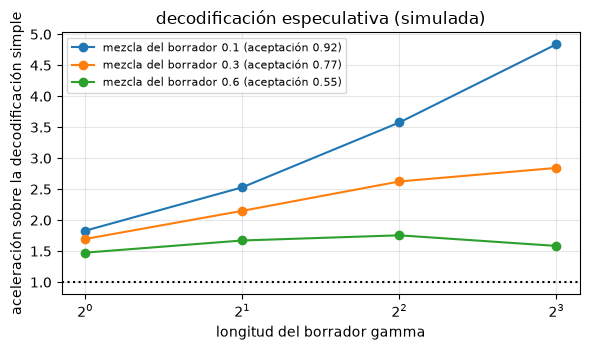

3 s


In [20]:
rs = np.random.default_rng(0)
VS = 24
P = rs.dirichlet(np.full(VS, 0.2), size=VS)                         # modelo objetivo: P[prev] = distribución del token siguiente
NOISE = rs.dirichlet(np.full(VS, 0.2), size=VS)
def draft_of(mix): return (1 - mix) * P + mix * NOISE               # modelo borrador: el objetivo difuminado hacia otra distribución

def sample_plain(n, rng):
    out = [0]
    for _ in range(n): out.append(rng.choice(VS, p=P[out[-1]]))
    return np.array(out)

def sample_spec(n, Q, gamma, rng):
    out = [0]; calls = acc = prop = 0
    while len(out) < n + 1:
        prev = out[-1]; drafts = []; qs = []; cur = prev
        for _ in range(gamma):                                      # el borrador propone gamma tokens
            x = rng.choice(VS, p=Q[cur]); drafts.append(x); qs.append(Q[cur]); cur = x
        calls += 1                                                  # un paso del objetivo puntúa todos
        cur = prev; new = []; all_ok = True
        for x, q in zip(drafts, qs):
            p = P[cur]; prop += 1
            if rng.random() < min(1.0, p[x] / q[x]):
                new.append(x); acc += 1; cur = x
            else:
                r = np.maximum(p - q, 0); new.append(rng.choice(VS, p=r / r.sum())); all_ok = False; break
        if all_ok: new.append(rng.choice(VS, p=P[cur]))             # token extra del objetivo
        out += new
    return np.array(out[: n + 1]), calls, acc / prop

def transition_error(seq):                                          # distancia de variación total ponderada por visitas a la P verdadera
    C = np.zeros((VS, VS)); np.add.at(C, (seq[:-1], seq[1:]), 1)
    w = C.sum(1) / C.sum(); E = C / np.maximum(C.sum(1, keepdims=True), 1)
    return float((w * 0.5 * np.abs(E - P).sum(1)).sum())

t0 = time.time()
s_plain = sample_plain(60000, np.random.default_rng(1))
s_spec, _, _ = sample_spec(60000, draft_of(0.3), 4, np.random.default_rng(2))
print(f"distancia de las transiciones empíricas al objetivo (60 000 tokens): muestreo simple {transition_error(s_plain):.4f}, especulativo (mezcla 0.3, gamma 4) {transition_error(s_spec):.4f}")

COST = 0.05                                                         # un paso del borrador cuesta el 5 % de un paso del objetivo
table = {}
print(f"\n{'mezcla borr.':>9s} {'gamma':>5s} {'aceptación':>11s} {'tokens/paso':>12s} {'fórmula':>8s} {'aceleración (c = 0.05)':>20s}")
for mix in [0.1, 0.3, 0.6]:
    for gamma in [1, 2, 4, 8]:
        seq, calls, alpha = sample_spec(10000, draft_of(mix), gamma, np.random.default_rng(3))
        tpp = (len(seq) - 1) / calls; formula = (1 - alpha ** (gamma + 1)) / (1 - alpha)
        table[(mix, gamma)] = (alpha, tpp, tpp / (gamma * COST + 1))
        print(f"{mix:9.1f} {gamma:5d} {alpha:11.2f} {tpp:12.2f} {formula:8.2f} {tpp / (gamma * COST + 1):19.2f}x")
fig, ax = plt.subplots(figsize=(6, 3.6))
for mix in [0.1, 0.3, 0.6]: ax.plot([1, 2, 4, 8], [table[(mix, g_)][2] for g_ in [1, 2, 4, 8]], "o-", label=f"mezcla del borrador {mix} (aceptación {table[(mix, 4)][0]:.2f})")
ax.axhline(1, color="k", ls=":"); ax.set_xlabel("longitud del borrador gamma"); ax.set_ylabel("aceleración sobre la decodificación simple"); ax.set_xscale("log", base=2); ax.legend(fontsize=8); ax.set_title("decodificación especulativa (simulada)")
plt.tight_layout(); plt.show(); print(f"{time.time() - t0:.0f} s")

**Lectura.** La salida es estadísticamente indistinguible del muestreo simple del objetivo (las distancias a las probabilidades de transición verdaderas son 0.024 para el muestreo simple y 0.023 para la decodificación especulativa, ambas error de muestreo de 60 000 tokens), así que la decodificación especulativa es **sin pérdidas**: cambia la velocidad y no la distribución. Los tokens por paso del objetivo coinciden con la fórmula hasta dos decimales (la fórmula supone la misma probabilidad de aceptación en cada posición; en nuestro juguete la aceptación depende del token actual, y aun así el ajuste es cercano). La aceleración la gobierna la aceptación: un borrador que coincide con el objetivo el 92 % de las veces da 4.3 tokens por paso con $\gamma = 4$ y una aceleración de 3.6 (4.8 con $\gamma = 8$) cuando el borrador cuesta el 5 % del objetivo; con un 77 % de aceptación la aceleración es de unas 2.6, y con un 55 % de unas 1.5 a 1.8, donde un borrador más largo ($\gamma = 8$) ya es peor que $\gamma = 4$ porque se desperdician propuestas. La simulación usa un borrador artificial, un lenguaje de juguete y una razón de costes supuesta; en la práctica el borrador es un modelo más pequeño de la misma familia y las aceleraciones que dan los artículos son de 2 a 3 veces.

La **destilación** entrena a un **estudiante** pequeño para imitar a un **maestro** grande. En lugar de solo la etiqueta dura, el estudiante imita la distribución de salida **blanda** del maestro a una temperatura elevada $T$ (Hinton et al., 2015): la pérdida es $(1-\lambda)\,\mathrm{CE}(y, \text{student}) + \lambda\, T^2\, \mathrm{KL}\big(\text{teacher}_T \,\|\, \text{student}_T\big)$, donde $\text{teacher}_T$ es el softmax del maestro con los logits divididos por $T$. Los objetivos blandos llevan información sobre qué clases erróneas son plausibles ("un 3 se parece un poco a un 8"), que las etiquetas duras no tienen. Muchos modelos abiertos pequeños se destilan de otros mayores; la parte de ajuste fino de esto está en el [módulo 02 de Neural Networks 1002](https://neural-networks-1002.academy.forwardforecasting.eu/es/02-modelos-abiertos-y-ajuste-fino/). Una pequeña medición en el conjunto de dígitos de 8 por 8 de scikit-learn (1797 imágenes, 8 por 8 píxeles; licencia CC BY 4.0, [doi:10.24432/C50P49](https://doi.org/10.24432/C50P49)), con solo 150 imágenes de entrenamiento etiquetadas; el maestro etiqueta también las demás imágenes de entrenamiento (que no tienen etiquetas), y el estudiante aprende de esas etiquetas blandas además de las 150 verdaderas:

In [21]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
dg = load_digits()
Xd = torch.tensor(dg.data / 16.0, dtype=torch.float32); yd = torch.tensor(dg.target)
accs = {"maestro (256-256, 150 etiquetas)": [], "estudiante, 150 etiquetas": [], "estudiante, imágenes etiquetadas por el maestro": []}
for seed in range(5):
    Xa, Xt, ya, yt = train_test_split(Xd, yd, test_size=0.4, random_state=seed, stratify=yd)
    XL, yL = Xa[:150], ya[:150]                                      # solo 150 imágenes tienen etiqueta; las demás (Xa) no están etiquetadas
    def fit_mlp(h, loss_fn, epochs=300):
        torch.manual_seed(seed)
        net = nn.Sequential(nn.Linear(64, h), nn.ReLU(), nn.Linear(h, h), nn.ReLU(), nn.Linear(h, 10)) if h > 16 else nn.Sequential(nn.Linear(64, h), nn.ReLU(), nn.Linear(h, 10))
        opt = torch.optim.Adam(net.parameters(), 3e-3)
        for _ in range(epochs):
            loss = loss_fn(net); opt.zero_grad(); loss.backward(); opt.step()
        with torch.no_grad(): return net, (net(Xt).argmax(-1) == yt).float().mean().item()
    teacher, a_t = fit_mlp(256, lambda net: F.cross_entropy(net(XL), yL))
    _, a_h = fit_mlp(8, lambda net: F.cross_entropy(net(XL), yL))
    with torch.no_grad(): soft = F.softmax(teacher(Xa) / 3.0, -1)    # el maestro etiqueta todas las imágenes de entrenamiento, tengan etiqueta o no
    _, a_d = fit_mlp(8, lambda net: 0.3 * F.cross_entropy(net(XL), yL) + 0.7 * 9 * F.kl_div(F.log_softmax(net(Xa) / 3.0, -1), soft, reduction="batchmean"))
    for key, a_ in zip(accs, (a_t, a_h, a_d)): accs[key].append(a_)
print(f"exactitud de prueba en {len(Xt)} dígitos apartados, 150 imágenes de entrenamiento etiquetadas, 5 particiones (media, desv. típica):")
for key, v in accs.items():
    print(f"  {key:48s} {np.mean(v):.3f} +- {np.std(v):.3f}")
n_teacher = 64 * 256 + 256 + 256 * 256 + 256 + 256 * 10 + 10; n_student = 64 * 8 + 8 + 8 * 10 + 10
print(f"parámetros: maestro {n_teacher:,}, estudiante {n_student:,} ({n_teacher / n_student:.0f}x menor)")

exactitud de prueba en 719 dígitos apartados, 150 imágenes de entrenamiento etiquetadas, 5 particiones (media, desv. típica):
  maestro (256-256, 150 etiquetas)                 0.909 +- 0.006
  estudiante, 150 etiquetas                        0.856 +- 0.039
  estudiante, imágenes etiquetadas por el maestro  0.871 +- 0.028
parámetros: maestro 85,002, estudiante 610 (139x menor)


**Lectura.** El estudiante de 610 parámetros conserva la mayor parte de la exactitud del maestro de 85 000 parámetros (de 0.86 a 0.87 frente a 0.91), y el estudiante que además aprende de las etiquetas blandas del maestro sobre las imágenes sin etiquetar lo hace algo mejor que el mismo estudiante entrenado solo con las 150 etiquetas (0.871 frente a 0.856); la ganancia de 0.015 es menor que la desviación típica entre particiones (0.03 más o menos), así que en este problema diminuto la destilación es sugerente, no demostrada. El efecto que se describe en la literatura es mayor cuando el maestro sabe mucho más de lo que dicen los datos etiquetados (un modelo de lenguaje grande supervisando a uno pequeño con millones de ejemplos generados). La cuantización, la decodificación especulativa y la destilación son complementarias: se destila a un modelo pequeño, se cuantiza y se usa como borrador de uno mayor.

## 9. Energía y coste

Todo lo anterior trata en último término de julios y de euros. Una contabilidad aproximada necesita tres números: el **cómputo** ($6ND$ para el entrenamiento, $2N$ por token para la inferencia), la **eficiencia del hardware** (qué parte del pico del acelerador se aprovecha realmente, sección 1) y la **potencia** que consume el hardware. La energía de una ejecución de entrenamiento son las horas de acelerador por la potencia, normalmente multiplicadas por la **eficiencia en el uso de la energía** (PUE, power usage effectiveness: energía total de la instalación dividida por la energía de los equipos informáticos, típicamente de 1.1 a 1.5) por la refrigeración y otros gastos; las emisiones son la energía por la intensidad de carbono de la electricidad, que varía en un factor de 10 o más entre regiones y horas (Patterson et al., 2021). Son estimaciones con gran incertidumbre: los informes publicados discrepan en lo que incluyen (solo los chips, el servidor entero, el centro de datos, las ejecuciones de investigación previas a la final, la fabricación del hardware).

Para la inferencia los mismos dos regímenes de la sección 8 dan un **rango** y no un número: con tamaño de lote 1 cada token cuesta el tiempo de leer todos los pesos ($\text{bytes} / \text{ancho de banda}$) por la potencia, y con lotes grandes el acelerador pasa a estar limitado por cómputo y cada token cuesta $2N / (\text{pico} \times \text{utilización})$ por la potencia.

In [22]:
# entrenamiento: horas de GPU y potencia publicadas (artículo de Llama 2, Tabla 2) y la estimación publicada de GPT-3 (Patterson et al.)
print("ENTRENAMIENTO")
llama = {"Llama-2 7B": (184_320, 31.22), "Llama-2 70B": (1_720_320, 291.42)}
for name, (hours, published_t) in llama.items():
    mwh = hours * 400 / 1e6                                              # 400 W por A100-80GB, solo GPU
    print(f"  {name:12s} {hours:>9,} horas de GPU x 400 W = {mwh:7.1f} MWh (solo GPU); a 0.423 kg CO2e/kWh = {mwh * 0.423:6.1f} t CO2e   (publicado: {published_t} t)")
print("  GPT-3 175B   estimación de Patterson et al.: 1287 MWh y 552 t CO2e, con unas 10 000 GPU V100 durante unos 15 días")
home = 3.5                                                               # MWh por año de un hogar típico en Europa (orden de magnitud)
print(f"  para dar escala: 1287 MWh es la electricidad anual de unos {1287 / home:,.0f} hogares a {home} MWh por año (un supuesto)")

# inferencia: energía por token generado en un acelerador de clase H100 (supuesto: 700 W, 3.35 TB/s, 989 TFLOP/s bf16 denso)
POWER, BW, PEAK = 700.0, 3.35e12, 989e12
print("\nINFERENCIA (solo el acelerador, orden de magnitud, pesos bf16)")
print(f"{'modelo':12s} {'lote 1 (limitado por memoria)':>24s} {'lote grande, 30% de utilización':>30s} {'respuesta de 500 tokens':>24s}")
inf = {}
for name, n in [("7B dense", 7e9), ("70B dense", 70e9), ("MoE 1.3B/0.4B", 0.4e9)]:
    store = 2 * (1.3e9 if name.startswith("MoE") else n)                # bytes leídos por paso: todos los pesos
    j_b1 = POWER * store / BW                                           # julios por token con lote 1
    j_bat = POWER * (2 * n) / (PEAK * 0.3)                              # julios por token cuando está limitado por cómputo
    inf[name] = (j_b1, j_bat)
    print(f"{name:12s} {j_b1:18.2f} J/token {j_bat:24.3f} J/token {500 * j_bat / 3600:10.3f} a {500 * j_b1 / 3600:6.2f} Wh")

e_train_wh = 184_320 * 400                                              # energía de entrenamiento de Llama-2 7B en Wh (solo GPU)
for name in ["7B dense"]:
    j_b1, j_bat = inf[name]
    print(f"\nequilibrio para el modelo de 7B: la energía del entrenamiento equivale a la de inferencia de unas "
          f"{e_train_wh * 3600 / (500 * j_bat):.1e} (en lotes) a {e_train_wh * 3600 / (500 * j_b1):.1e} (lote 1) respuestas de 500 tokens")

ENTRENAMIENTO
  Llama-2 7B     184,320 horas de GPU x 400 W =    73.7 MWh (solo GPU); a 0.423 kg CO2e/kWh =   31.2 t CO2e   (publicado: 31.22 t)
  Llama-2 70B  1,720,320 horas de GPU x 400 W =   688.1 MWh (solo GPU); a 0.423 kg CO2e/kWh =  291.1 t CO2e   (publicado: 291.42 t)
  GPT-3 175B   estimación de Patterson et al.: 1287 MWh y 552 t CO2e, con unas 10 000 GPU V100 durante unos 15 días
  para dar escala: 1287 MWh es la electricidad anual de unos 368 hogares a 3.5 MWh por año (un supuesto)

INFERENCIA (solo el acelerador, orden de magnitud, pesos bf16)
modelo       lote 1 (limitado por memoria) lote grande, 30% de utilización  respuesta de 500 tokens
7B dense                   2.93 J/token                    0.033 J/token      0.005 a   0.41 Wh
70B dense                 29.25 J/token                    0.330 J/token      0.046 a   4.06 Wh
MoE 1.3B/0.4B               0.54 J/token                    0.002 J/token      0.000 a   0.08 Wh

equilibrio para el modelo de 7B: la energía del 

**Lectura.** Las cifras reproducen las publicadas: 184 320 horas de GPU a 400 W son 73.7 MWh, que a 0.423 kg de CO2 equivalente por kWh da las 31.2 toneladas que da el artículo de Llama 2 para el modelo de 7B (y 291 toneladas para el de 70B), y Patterson et al. estiman 1287 MWh para GPT-3. Esto cubre solo los aceleradores de la ejecución final del entrenamiento. Las líneas de inferencia muestran lo que es fácil pasar por alto: **la energía por token varía unos dos órdenes de magnitud según lo bien que se use el acelerador** (con lote 1 se leen todos los pesos para un token, un lote lleno reparte cada lectura de pesos entre cientos de tokens), así que la eficiencia al servir (agrupar en lotes, cuantización, decodificación especulativa, MoE, modelos más pequeños) importa tanto como la arquitectura. Una respuesta de 500 tokens del modelo de 7B cuesta de 0.005 a 0.4 Wh solo en el acelerador (nuestros supuestos: un acelerador de 700 W y una utilización idealizada; los despliegues reales añaden máquinas anfitrionas, refrigeración y capacidad ociosa). La línea de equilibrio muestra por qué un modelo muy usado puede gastar más energía en inferencia que en entrenamiento: los 74 MWh del entrenamiento equivalen a la inferencia de entre 180 millones (lote 1) y 16 000 millones (lotes grandes) de respuestas de 500 tokens, cifra que un servicio con millones de usuarios diarios alcanza en meses o unos pocos años. Trata estos números como órdenes de magnitud, da los supuestos junto con ellos y prefiere medir en tu propio hardware (medidor de potencia o contadores del fabricante) cuando la decisión dependa de ello.

## Ideas clave

* **El coste tiene una fórmula.** El entrenamiento cuesta unos $6ND$ FLOPs, guarda unos 16 bytes por parámetro de estado y, en la inferencia, una caché KV de $2 L\, n_\text{kv}\, d_\text{head}$ números por token. La regla coincidió con un total de FLOPs contado y con el cómputo publicado de GPT-3 (sección 1); las ejecuciones reales alcanzan del 30 al 45 % del pico del acelerador.
* **FlashAttention es exacta.** Los bloques con el softmax en línea dan la misma salida que la atención estándar hasta el error de redondeo sin construir nunca la matriz $n \times n$; la memoria baja de cuadrática a lineal, la aritmética sigue siendo cuadrática (sección 2).
* **Compartir claves y valores reduce la caché.** MQA y GQA reducen la caché KV en proporción al número de cabezas de clave/valor (medido: 16 veces); a esta escala GQA con 2 grupos no costó nada medible y una sola cabeza 0.03 nats (una semilla, sección 3).
* **RoPE hace la atención relativa; las ventanas acotan el coste.** La puntuación depende solo del desplazamiento, y las ventanas apiladas alcanzan $L(w-1)+1$ tokens (sección 4).
* **MoE desacopla la capacidad del cómputo** (unos 1300 millones almacenados y 400 millones usados por token en un modelo real) pero no de la memoria, y necesita una pérdida de balance contra el colapso de expertos (sección 5).
* **Los modelos de espacio de estados cambian recuerdo exacto por un estado constante.** La recurrencia es un escaneo paralelo; la selectividad es lo que deja al estado elegir qué conservar; en nuestro juguete el modelo selectivo encontró la aguja perfectamente con su longitud de entrenamiento y en parte hasta el doble (0.90 con 256, 0.49 con 512), mientras que la atención la encontró con todas las longitudes a un precio cuadrático (sección 6).
* **Entrenar a gran escala convierte una escasez en otra.** La precisión mixta (bf16 no necesita escalado de la pérdida; fp16 sí), la acumulación y el checkpointing cambian tiempo por memoria, el paralelismo de datos cambia comunicación por velocidad y se aplana cuando los pasos son pequeños (medido), y ZeRO/FSDP, el paralelismo de tensores y de tubería reparten lo que un dispositivo no puede guardar (sección 7).
* **La inferencia está limitada por el ancho de banda.** La cuantización reduce bytes, la decodificación especulativa no tiene pérdidas y sigue una fórmula sencilla, y la destilación traslada capacidad a un modelo más pequeño (sección 8).
* **La energía por token varía en órdenes de magnitud** con la utilización; el trabajo de eficiencia al servir importa tanto como la arquitectura (sección 9).

## Ejercicios

1. En la sección 1, añade Mistral 7B (32 capas, ancho 4096, 32 cabezas de consulta, 8 cabezas de clave/valor, tamaño oculto 14336, MLP con puerta, vocabulario 32000) a la calculadora. ¿Cuántos parámetros da la fórmula y cuál es la caché KV con 32 000 tokens?
2. En la sección 2, cambia el tamaño de bloque de la atención por bloques a 64 y a 1024. ¿Cómo cambian la memoria pico y el tiempo? ¿Por qué la versión por bloques acaba perdiendo su ventaja de memoria a medida que crecen los bloques?
3. En la sección 2, ejecuta el paso hacia atrás de la atención ingenua y de una versión que recalcula (usa `torch.utils.checkpoint` alrededor de la función de atención) con $n = 4096$. ¿Cuánta memoria ahorra la recomputación?
4. En la sección 3, entrena el modelo de lenguaje 800 pasos con tres semillas por configuración. ¿Es ahora la diferencia entre 8, 2 y 1 cabezas de clave/valor mayor que el ruido de las semillas?
5. En la sección 4, implementa la interpolación de posiciones: escala las posiciones por $1/2$ y comprueba que las puntuaciones a distancia 100 pasan a ser iguales a las puntuaciones a distancia 50 del modelo sin escalar.
6. En la sección 5, haz que las frecuencias de los grupos sean desiguales (el grupo $c$ tiene probabilidad proporcional a $1/(c+1)$). ¿Qué hace ahora la pérdida de balance con la calidad? ¿Sigue siendo la carga perfectamente pareja el objetivo?
7. En la sección 5, añade un límite de capacidad (cada experto acepta como máximo 1.25 veces su parte justa de tokens de un lote, los tokens sobrantes se descartan) y mide cuántos tokens se descartan con y sin la pérdida de balance.
8. En la sección 6, entrena los tres modelos de la aguja con longitud 512 en lugar de 128, y después con una mezcla de longitudes. ¿Extrapola ahora el SSM selectivo a 2048? ¿Qué efecto tiene el tamaño del estado $N$?
9. En la sección 7.3, duplica el tamaño del modelo (ancho de 256 a 512) con un lote global de 4. ¿Cómo cambia la aceleración con cuatro trabajadores, y por qué?
10. En la sección 8, encuentra la longitud de borrador $\gamma$ que maximiza la aceleración para una mezcla de borrador de 0.3 y razones de coste $c$ de 0.02, 0.05 y 0.2. ¿La mejor $\gamma$ crece o se reduce con $c$?
11. En la sección 9, rehaz la tabla de inferencia para un modelo de 70B con 2 bits por peso (unos 0.25 bytes por parámetro) y para un contexto de 32 000 tokens con la caché KV de Llama-2 70B (leída en cada paso). ¿Qué término domina con lote 1?

## Referencias

* Kaplan, J. et al. (2020). Scaling laws for neural language models. arXiv:2001.08361: https://arxiv.org/abs/2001.08361
* Hoffmann, J. et al. (2022). Training compute-optimal large language models (Chinchilla). arXiv:2203.15556: https://arxiv.org/abs/2203.15556
* Brown, T. et al. (2020). Language models are few-shot learners (GPT-3). NeurIPS. arXiv:2005.14165: https://arxiv.org/abs/2005.14165
* Touvron, H. et al. (2023). Llama 2: open foundation and fine-tuned chat models. arXiv:2307.09288: https://arxiv.org/abs/2307.09288
* Korthikanti, V. et al. (2022). Reducing activation recomputation in large transformer models. arXiv:2205.05198: https://arxiv.org/abs/2205.05198
* Dao, T., Fu, D. Y., Ermon, S., Rudra, A. and Re, C. (2022). FlashAttention: fast and memory-efficient exact attention with IO-awareness. NeurIPS. arXiv:2205.14135: https://arxiv.org/abs/2205.14135
* Dao, T. (2023). FlashAttention-2: faster attention with better parallelism and work partitioning. arXiv:2307.08691: https://arxiv.org/abs/2307.08691
* Shazeer, N. (2019). Fast transformer decoding: one write-head is all you need (multi-query attention). arXiv:1911.02150: https://arxiv.org/abs/1911.02150
* Ainslie, J. et al. (2023). GQA: training generalized multi-query transformer models from multi-head checkpoints. EMNLP. arXiv:2305.13245: https://arxiv.org/abs/2305.13245
* Su, J. et al. (2021). RoFormer: enhanced transformer with rotary position embedding. arXiv:2104.09864: https://arxiv.org/abs/2104.09864
* Chen, S., Wong, S., Chen, L. and Tian, Y. (2023). Extending context window of large language models via positional interpolation. arXiv:2306.15595: https://arxiv.org/abs/2306.15595
* Jiang, A. Q. et al. (2023). Mistral 7B. arXiv:2310.06825: https://arxiv.org/abs/2310.06825
* Shazeer, N. et al. (2017). Outrageously large neural networks: the sparsely-gated mixture-of-experts layer. ICLR. arXiv:1701.06538: https://arxiv.org/abs/1701.06538
* Fedus, W., Zoph, B. and Shazeer, N. (2021). Switch Transformers: scaling to trillion parameter models with simple and efficient sparsity. JMLR 2022. arXiv:2101.03961: https://arxiv.org/abs/2101.03961
* IBM Granite team (2024). Granite 3.0 1B-A400M base model card (Apache 2.0): https://huggingface.co/ibm-granite/granite-3.0-1b-a400m-base
* Gu, A., Goel, K. and Re, C. (2022). Efficiently modeling long sequences with structured state spaces (S4). ICLR. arXiv:2111.00396: https://arxiv.org/abs/2111.00396
* Gu, A. and Dao, T. (2023). Mamba: linear-time sequence modeling with selective state spaces. arXiv:2312.00752: https://arxiv.org/abs/2312.00752
* Lieber, O. et al. (2024). Jamba: a hybrid Transformer-Mamba language model. arXiv:2403.19887: https://arxiv.org/abs/2403.19887
* Biderman, S. et al. (2023). Pythia: a suite for analyzing large language models across training and scaling. ICML. arXiv:2304.01373: https://arxiv.org/abs/2304.01373
* Micikevicius, P. et al. (2018). Mixed precision training. ICLR. arXiv:1710.03740: https://arxiv.org/abs/1710.03740
* Chen, T., Xu, B., Zhang, C. and Guestrin, C. (2016). Training deep nets with sublinear memory cost. arXiv:1604.06174: https://arxiv.org/abs/1604.06174
* Shoeybi, M. et al. (2019). Megatron-LM: training multi-billion parameter language models using model parallelism. arXiv:1909.08053: https://arxiv.org/abs/1909.08053
* Huang, Y. et al. (2019). GPipe: efficient training of giant neural networks using pipeline parallelism. NeurIPS. arXiv:1811.06965: https://arxiv.org/abs/1811.06965
* Rajbhandari, S., Rasley, J., Ruwase, O. and He, Y. (2020). ZeRO: memory optimizations toward training trillion parameter models. SC20. arXiv:1910.02054: https://arxiv.org/abs/1910.02054
* Zhao, Y. et al. (2023). PyTorch FSDP: experiences on scaling fully sharded data parallel. VLDB 2023. arXiv:2304.11277: https://arxiv.org/abs/2304.11277
* Leviathan, Y., Kalman, M. and Matias, Y. (2023). Fast inference from transformers via speculative decoding. ICML. arXiv:2211.17192: https://arxiv.org/abs/2211.17192
* Chen, C. et al. (2023). Accelerating large language model decoding with speculative sampling. arXiv:2302.01318: https://arxiv.org/abs/2302.01318
* Hinton, G., Vinyals, O. and Dean, J. (2015). Distilling the knowledge in a neural network. arXiv:1503.02531: https://arxiv.org/abs/1503.02531
* Patterson, D. et al. (2021). Carbon emissions and large neural network training. arXiv:2104.10350: https://arxiv.org/abs/2104.10350
* Alpaydin, E. and Kaynak, C. (1998). Optical Recognition of Handwritten Digits (UCI Machine Learning Repository, CC BY 4.0). https://doi.org/10.24432/C50P49

In [23]:
print(f"tiempo total de ejecución del cuaderno: {time.time() - T_START:.0f} s")

tiempo total de ejecución del cuaderno: 281 s
